# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL
### FINAL REPORT

---

### THÔNG TIN DỰ ÁN
- **Tên dự án:** Dự đoán học lực & Cảnh báo sớm sinh viên có nguy cơ học lại (Student Performance Analytics)
- **Mã lớp:** AI2102
- **Tên nhóm:** Nhóm 6
- **Thành viên nhóm:**
  1. Hoàng Văn Đức - HE210214 - Thành Viên
  2. Phạm Huy Vũ - HE210285 - Thành viên
  3. Nguyễn Tuấn Anh - HE210230 - Thành Viên
  4. Nguyễn Đình An - HE210153 - Thành Viên
- **Nguồn Dataset:** Open University Learning Analytics Dataset (OULAD) – UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/349 (DOI: 10.24432/C5KK69), giấy phép CC-BY 4.0


### 1.1: Bối cảnh bài toán và lý do thực hiện
- **Bối cảnh bài toán:** Ở các trường đại học, việc sinh viên trượt môn hoặc bỏ dở học phần gây thiệt hại cho cả hai phía. Sinh viên mất thêm học phí và thời gian, có nguy cơ chậm tốt nghiệp. Nhà trường thì giảm tỷ lệ tốt nghiệp đúng hạn và tốn thêm nguồn lực mở lớp học lại. Hiện nay việc phát hiện sinh viên gặp khó khăn chủ yếu dựa vào điểm giữa kỳ hoặc cuối kỳ, tức là khi đã quá muộn để can thiệp. Trong khi đó, hệ thống học trực tuyến (LMS/VLE) ghi lại hàng ngày dấu vết hành vi học tập: đăng nhập, truy cập tài liệu, nộp bài. Đây là nguồn dữ liệu có sẵn nhưng chưa được khai thác.
- **Vấn đề chính cần giải quyết:** Xác định những sinh viên có nguy cơ cao sẽ trượt (Fail) hoặc rút khỏi học phần (Withdrawn), tức là có nguy cơ phải học lại **ngay từ khi có được kết quả của các bài kiểm tra chiếm 40-50% trọng số điểm môn học** . Việc dự đoán chỉ dựa trên thông tin nền tảng, lịch sử học lại, hành vi trên VLE và kết quả các bài kiểm tra đầu tiên.
- **Giá trị/ Ý nghĩa đem lại:** Danh sách cảnh báo sớm giúp cố vấn học tập và giảng viên ưu tiên nguồn lực hỗ trợ có hạn (gọi điện, phụ đạo, tư vấn giảm tải) cho đúng người, vào lúc còn đủ thời gian để thay đổi kết quả. Các hệ thống tương tự như Course Signals tại Đại học Purdue (Arnold & Pistilli, 2012) và OU Analyse tại The Open University (Hlosta et al., 2017) đã chứng minh tính khả thi. Dự án dùng bộ dữ liệu OULAD của The Open University (Anh), gồm 32.593 lượt đăng ký học phần của sinh viên đại học.

### 1.2: Các câu hỏi cốt lõi
- **Câu hỏi 1:** Những yếu tố nào quan sát được trong 4 tháng đầu của học phần dự báo mạnh nhất việc sinh viên trượt hoặc bỏ học phần? Các yếu tố được xem xét gồm mức độ tương tác VLE, kết quả bài kiểm tra đầu tiên, số lần đã học lại và số tín chỉ đăng ký.
- **Câu hỏi 2:** Với nguồn lực tư vấn có hạn, mô hình cần đạt Recall bao nhiêu để phát hiện phần lớn sinh viên có nguy cơ? Mỗi mức rủi ro nên gắn với hành động can thiệp nào?

### 1.3: Chi tiết bài toán
- **Problem Type:** Học có giám sát (Supervised Learning), **phân loại 2 nhóm (binary classification)** (Binary Classification).
- **Đơn vị phân tích:** 1 dòng = 1 sinh viên × 1 lớp học phần (`code_module` + `code_presentation`).
- **Thời điểm dự đoán (cut-off):** Sau khi có đủ 40-50% trọng số điểm môn học kể từ khi học phần bắt đầu. Có hai lý do chọn mốc này:
  - Khi đạt được tầm 40-50% trọng số điểm của môn học, đã có ít nhất 2 bài kiểm tra được hoàn thành và ít nhất 60-90 ngày học để đánh giá dựa trên điểm số và lượng truy cập vào tài liệu học tập
  - Khi đó vẫn còn khoảng 45% thời lượng học phần (dài 100-120 ngày) để can thiệp.
- **Target Variable (y):** `at_risk` có hai giá trị:
  - `1` (có nguy cơ học lại): `final_result` là `Fail` hoặc `Withdrawn`.
  - `0` (an toàn): `final_result` là `Pass` hoặc `Distinction`.
- **Expected Feature Variables (X):**
  - Lịch sử học tập: số lần đã học học phần này (`num_of_prev_attempts`), số tín chỉ đang học.
  - Đăng ký: ngày đăng ký so với ngày khai giảng.
  - Hành vi VLE đến thời điểm dự đoán: tổng click, số ngày hoạt động, số tài nguyên truy cập, click trước khai giảng.
  - Đánh giá đến thời điểm dự đoán: số bài đến hạn, số bài đã nộp, điểm trung bình, số bài nộp trễ.
  - **Không dùng** các thông tin chỉ có sau mốc cut-off, như ngày rút học phần và điểm các bài sau thười điểm dự đoán, để tránh rò rỉ dữ liệu (data rò rỉ thông tin tương lai).
- **Evaluation Metric:**
  - Chỉ số chính: **Recall** của lớp `at_risk = 1` và **F1-Score**. Lý do là bỏ sót một sinh viên cần hỗ trợ (False Negative) tốn kém hơn nhiều so với một cuộc gọi tư vấn thừa (False Positive).
  - Chỉ số phụ: **PR-AUC** và **ROC-AUC** để so sánh mô hình độc lập với ngưỡng phân loại.

---
*Phần 1 (Business Understanding) giữ từ bản gốc. Phần 2 – 5 viết lại.*


# PART 2: THU THẬP DỮ LIỆU


### 2.1 Nguồn dữ liệu (Data Source)

| Thuộc tính | Mô tả |
|:---|:---|
| **Tên dataset** | Open University Learning Analytics Dataset (OULAD) |
| **Công bố gốc** | Kuzilek, Hlosta, Zdrahal (2017). *Scientific Data* 4:170171. DOI 10.1038/sdata.2017.171 |
| **Repository** | UCI ML Repository, id 349 (DOI 10.24432/C5KK69) |
| **Giấy phép** | CC-BY 4.0 |
| **Thời gian** | 4 kỳ: 2013B, 2013J, 2014B, 2014J (B=Feb, J=Oct) |
| **Phạm vi** | 32.593 lượt ghi danh × 7 bảng quan hệ |


### 2.2 Từ điển dữ liệu (Data Dictionary)

| Bảng | Số dòng | Khoá | Nội dung chính |
|:---|---:|:---|:---|
| `courses` | 22 | `(module, presentation)` | Danh sách lớp + độ dài kỳ (ngày) |
| `assessments` | 206 | `id_assessment` | Loại (bài TMA/CMA/Exam), ngày đến hạn, trọng số % |
| `vle` | 6.364 | `id_site` | Tài nguyên học + activity_type |
| `studentInfo` | 32.593 | `(module, pres, id_student)` | **Thông tin SV + `final_result`** |
| `studentRegistration` | 32.593 | như trên | `date_registration`, `date_unregistration` |
| `studentAssessment` | 173.912 | `(id_assessment, id_student)` | `score` + `date_submitted` |
| `studentVle` | **10.655.280** | long format | Log click hàng ngày: `(id_site, date, sum_click)` |

**Note anonymization:** cột `date` được chuẩn hoá về **ngày tương đối so với ngày khai giảng kỳ** (date < 0 = trước khai giảng).


### 2.3 Nạp 7 bảng gốc (Data Loading)

Tải cả 7 bảng — kể cả `studentVle` 10.6M dòng — dùng `chunksize` để không ngốn RAM đột ngột. Mọi giá trị `?` được coi là null; tên cột và giá trị string được `strip()` vì header gốc có khoảng trắng dư sau dấu phẩy.


In [1]:
import pandas as pd
import numpy as np
import sqlite3
from pathlib import Path

# Đường dẫn cố định: notebook nằm trong G6/, dữ liệu gốc nằm ở ../prj/
PRJ = Path('../prj')
G6  = Path('.')
DB_PATH  = G6 / 'oulad.db'
SQL_PATH = G6 / 'integrate.sql'
OUT_CSV  = G6 / 'Intergrated_data.csv'

def load_clean(name):
    # Lý do strip header + value: header 4 bảng OULAD gốc có khoảng trắng sau dấu phẩy
    # (ví dụ ' "code_presentation"'), nếu không strip thì JOIN key sẽ lệch.
    df = pd.read_csv(PRJ / f'{name}.csv', na_values=['?'], skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    for c in df.select_dtypes(include=['object','string']).columns:
        df[c] = df[c].astype('string').str.strip()
    return df

courses = load_clean('courses')
assessments = load_clean('assessments')
# Ép date/weight sang số: trong CSV là string, nếu không ép thì SQL CAST("") = 0 → sai cutoff.
assessments['date']   = pd.to_numeric(assessments['date'],   errors='coerce')
assessments['weight'] = pd.to_numeric(assessments['weight'], errors='coerce')
courses['module_presentation_length'] = pd.to_numeric(
    courses['module_presentation_length'], errors='coerce')

vle                 = load_clean('vle')
studentInfo         = load_clean('studentInfo')
studentRegistration = load_clean('studentRegistration')
studentAssessment   = load_clean('studentAssessment')

# In shape của 6 bảng vừa nạp để chắc file nào cũng đọc đúng (ví dụ studentInfo phải có đúng 32.593 dòng).
for name, df in [('courses',courses),('assessments',assessments),('vle',vle),
                  ('studentInfo',studentInfo),('studentRegistration',studentRegistration),
                  ('studentAssessment',studentAssessment)]:
    print(f'  {name:22s} shape={df.shape}')


  courses                shape=(22, 3)
  assessments            shape=(206, 6)
  vle                    shape=(6364, 6)
  studentInfo            shape=(32593, 12)
  studentRegistration    shape=(32593, 5)
  studentAssessment      shape=(173912, 5)


**Nhận xét.** 6 bảng nhỏ nạp trong vài giây. `studentInfo` khớp 32.593 dòng (bảng trung tâm), `studentAssessment` 173.912 lượt nộp bài. Tiếp theo sẽ đưa toàn bộ vào SQLite, bao gồm `studentVle` chunked.


### 2.4 Tích hợp dữ liệu bằng SQL

Trong `G6/integrate.sql`: dùng 4 bảng tạm trong SQL (Common Table Expression — CTE) (`module_cutoff`, `vle_agg`, `due_agg`, `assess_agg`) + 1 view `df_raw_v`. Kết quả đã export sẵn vào `G6/Intergrated_data.csv` (25.219 dòng × 17 cột). Mở file SQL bằng SQL IntelliView để xem/chạy lại.


In [2]:
# Pipeline SQL đã được tích hợp sẵn vào G6/Intergrated_data.csv ở lần chạy trước.
# Để tái lập toàn bộ pipeline từ CSV gốc → SQLite → SQL, mở G6/integrate.sql
# bằng SQL IntelliView hoặc chạy script build DB kèm theo. Ở đây ta sử dụng
# trực tiếp kết quả đã tích hợp để tập trung phân tích.
# Kiểm tra 2 artefact của pipeline SQL đang tồn tại và đã export CSV đúng.
from pathlib import Path
print(f'G6/integrate.sql tồn tại: {(G6/"integrate.sql").exists()}')
print(f'G6/Intergrated_data.csv kích thước: {(G6/"Intergrated_data.csv").stat().st_size/1e6:.2f} MB')


G6/integrate.sql tồn tại: True
G6/Intergrated_data.csv kích thước: 1.67 MB


**Nhận xét.** DB ~560 MB (chủ yếu là `studentVle`). Có thể mở `G6/oulad.db` bằng SQL IntelliView để query độc lập.


### 2.5 Nạp kết quả tích hợp


In [3]:
# Kiểm tra file SQL + file CSV đã có sẵn.
print(f'G6/integrate.sql: {SQL_PATH.exists()}, {SQL_PATH.stat().st_size:,} bytes')
print(f'G6/Intergrated_data.csv: {OUT_CSV.exists()}, {OUT_CSV.stat().st_size/1e6:.2f} MB')


G6/integrate.sql: True, 10,191 bytes
G6/Intergrated_data.csv: True, 1.67 MB


In [4]:
# Nạp dữ liệu đã tích hợp vào df_raw và in 3 chỉ số kiểm chứng:
#   (1) shape để chắc đủ 25.219 dòng × 17 cột sau scope filter
#   (2) at_risk rate để biết độ lệch lớp
#   (3) phân bố theo kỳ để kiểm temporal split sau này có đủ 4 kỳ
df_raw = pd.read_csv(OUT_CSV)

print(f'=== df_raw ===  shape = {df_raw.shape}')
print(f'at_risk rate = {df_raw["at_risk"].mean():.3f}')
print(f'Phân bố theo kỳ:')
print(df_raw['code_presentation'].value_counts().sort_index())


=== df_raw ===  shape = (25219, 17)
at_risk rate = 0.390
Phân bố theo kỳ:
code_presentation
2013B    3760
2013J    7207
2014B    5948
2014J    8304
Name: count, dtype: int64


**Nhận xét.** `cutoff_day` thay đổi theo module (EEE 68 ngày, GGG 222 ngày) nên không dùng được 1 ngày cố định. Sau lọc phạm vi đối tượng (scope filter) còn 25.219 dòng, at_risk ~39 % — lệch nhẹ nên dùng trọng số lớp cân bằng (trọng số lớp cân bằng (`trọng số lớp (class_weight)='balanced'`)).


# PART 3: LÀM SẠCH & TIỀN XỬ LÝ


Quy trình **1 mạch nhất quán** — không lặp vòng:
`Pre-check → Dtype → Missing → Outlier → Export df_clean`.

Kết thúc Part 3, `df_clean` sẵn sàng cho EDA (Part 4) — **không đụng vào nữa**.


### 3.1 Kiểm tra dữ liệu trước xử lý

Xác nhận schema, kiểu dữ liệu, đơn vị phân tích và phân bố target. Bỏ qua bước này là nguồn lỗi phổ biến nhất trong pipeline.


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 120,
    'font.size': 15,
    'axes.titlesize': 17,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13,
    'figure.titlesize': 18,
    'lines.linewidth': 2.2,
})
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
RNG = 42

# Load lại df_raw và in shape/info/head để nắm schema trước khi làm sạch.
df = pd.read_csv(OUT_CSV)

print('--- df.shape ---')
print(df.shape)
print('\n--- df.info() ---')
df.info()
print('\n--- df.head() ---')
df.head()


--- df.shape ---
(25219, 17)

--- df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 25219 entries, 0 to 25218
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           25219 non-null  str    
 1   code_presentation     25219 non-null  str    
 2   id_student            25219 non-null  int64  
 3   num_of_prev_attempts  25219 non-null  int64  
 4   studied_credits       25219 non-null  int64  
 5   date_registration     25212 non-null  float64
 6   cutoff_day            25219 non-null  int64  
 7   total_clicks          25219 non-null  int64  
 8   active_days           25219 non-null  int64  
 9   n_resources           25219 non-null  int64  
 10  clicks_before_start   25219 non-null  int64  
 11  n_assess_due          25219 non-null  int64  
 12  n_submitted           25219 non-null  int64  
 13  avg_score             21489 non-null  float64
 14  n_late                25219 non-n

,code_module,code_presentation,id_student,num_of_prev_attempts,studied_credits,date_registration,cutoff_day,total_clicks,active_days,n_resources,clicks_before_start,n_assess_due,n_submitted,avg_score,n_late,final_result,at_risk
0,AAA,2013J,11391,0,240,-159.0,117,628,26,39,98,2,2,81.5,0,Pass,0
1,AAA,2013J,28400,0,60,-53.0,117,896,45,53,215,2,2,69.0,1,Pass,0
2,AAA,2013J,31604,0,60,-52.0,117,1229,67,55,169,2,2,71.5,0,Pass,0
3,AAA,2013J,32885,0,60,-176.0,117,747,40,48,295,2,2,49.5,2,Pass,0
4,AAA,2013J,38053,0,60,-110.0,117,1238,69,51,277,2,2,74.0,1,Pass,0


In [6]:
# Đếm số dòng trùng theo (module, kỳ, id_student) — đơn vị phân tích của bài toán.
# Mục đích: nếu > 0 nghĩa là SQL JOIN sai, phải fix trước khi làm tiếp.
unit_dup = df.duplicated(subset=['code_module','code_presentation','id_student']).sum()
print(f'Trùng theo đơn vị phân tích: {unit_dup}')
print(f'Số lớp (module × presentation): {df.groupby(["code_module","code_presentation"]).ngroups}')
print(f'Số SV duy nhất: {df["id_student"].nunique():,}')


Trùng theo đơn vị phân tích: 0
Số lớp (module × presentation): 22
Số SV duy nhất: 23,153


**Nhận xét.** 0 duplicate theo (module, kỳ, id_student) — SQL JOIN đúng. 22 lớp, 4 kỳ phân bố cân cho chia theo thời gian (temporal split).


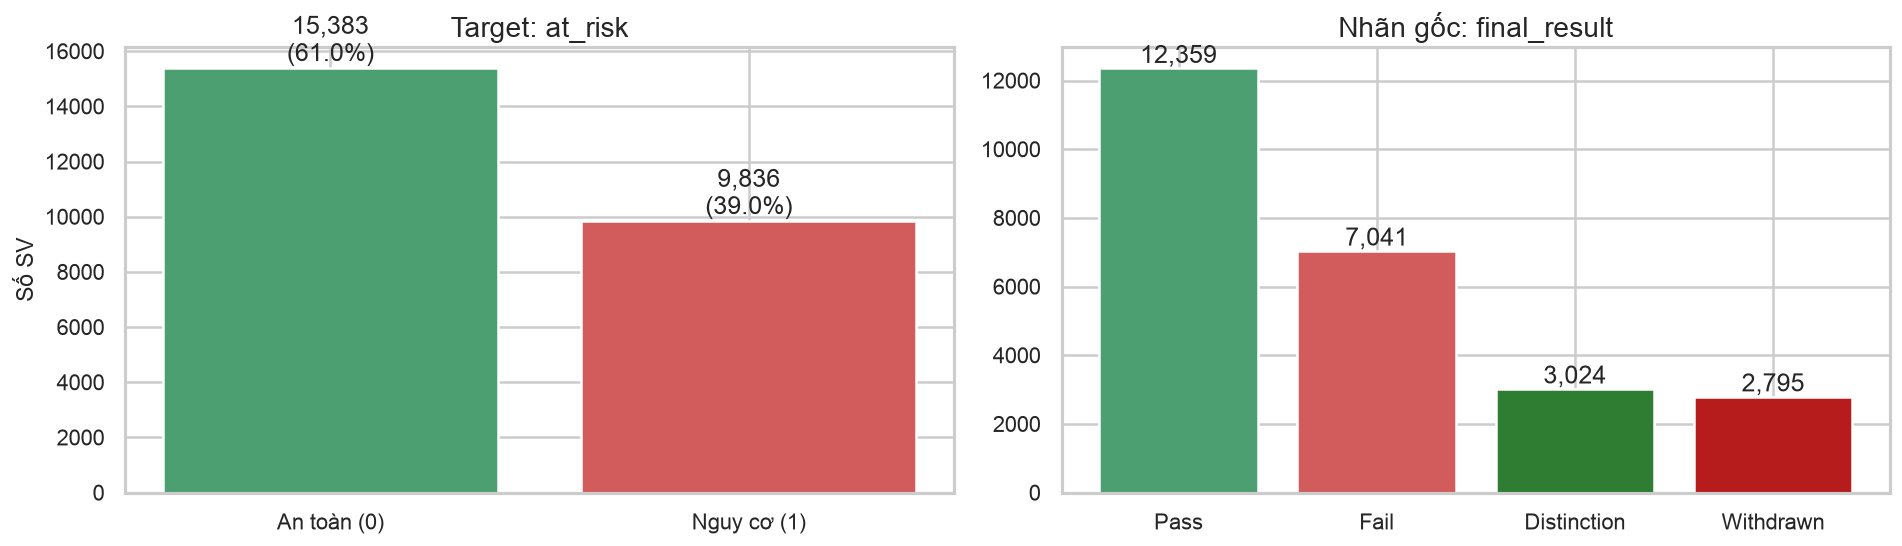

In [7]:
# Phân bố nhãn target
fig, axes = plt.subplots(1, 2, figsize=(16.1, 4.8))
vc = df['at_risk'].value_counts().sort_index()
axes[0].bar(['An toàn (0)','Nguy cơ (1)'], vc.values, color=['#4C9F70','#D25C5C'])
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', va='bottom')
axes[0].set_title('Target: at_risk'); axes[0].set_ylabel('Số SV')

fr = df['final_result'].value_counts()
axes[1].bar(fr.index, fr.values, color=['#4C9F70','#D25C5C','#2E7D32','#B71C1C'])
for i, v in enumerate(fr.values):
    axes[1].text(i, v, f'{v:,}', ha='center', va='bottom')
axes[1].set_title('Nhãn gốc: final_result')
plt.tight_layout(); plt.show()


**Nhận xét.** **61% an toàn / 39% nguy cơ** — lệch nhẹ (không cực đoan), nên không cần sinh thêm sinh viên nguy cơ giả (SMOTE), chỉ cần cho mô hình trừng phạt FN nặng hơn qua trọng số lớp cân bằng (`trọng số lớp (class_weight)='balanced'`). `Fail (trượt) + Withdrawn (bỏ học giữa chừng) → at_risk=1` vì cả 2 nhóm đều cần can thiệp sớm.


### 3.2 Chuẩn hoá kiểu dữ liệu

`id_student` về `str` (vì là mã định danh), các cột đếm về `int32`, cột phân loại về `category`, tách `code_presentation` thành `pres_year` + `pres_semester`. Hàm này dùng lại ở Part 5 khi đọc CSV features.


In [8]:
# Hàm chuẩn hoá kiểu dữ liệu — dùng lại ở Part 5 khi đọc features.csv từ đĩa.
# Khi save/load qua CSV, mọi int32 bị đẩy thành int64 và str/category thành object mặc định —
# do đó phải áp dụng lại quy ước kiểu mỗi lần đọc.
def normalize_dtypes(df):
    df = df.copy()
    if 'id_student' in df.columns:
        df['id_student'] = df['id_student'].astype(str)
    if 'code_presentation' in df.columns:
        df['pres_year']     = df['code_presentation'].str[:4].astype(int)
        df['pres_semester'] = df['code_presentation'].str[-1].map({'B':'Feb','J':'Oct'})
        df['code_presentation'] = df['code_presentation'].astype('category')
    if 'code_module' in df.columns:
        df['code_module'] = df['code_module'].astype('category')
    if 'pres_semester' in df.columns and df['pres_semester'].dtype.name != 'category':
        df['pres_semester'] = df['pres_semester'].astype('category')
    if 'final_result' in df.columns:
        df['final_result'] = df['final_result'].astype('category')
    int_cols = ['num_of_prev_attempts','studied_credits','cutoff_day','total_clicks',
                'active_days','n_resources','clicks_before_start','n_assess_due',
                'n_submitted','n_late','at_risk']
    for c in int_cols:
        if c in df.columns:
            df[c] = df[c].astype('int32')
    int8_cols = ['dropout_no_activity','active_but_no_submission','pending_grade',
                 'is_repeater']
    for c in int8_cols:
        if c in df.columns:
            df[c] = df[c].astype('int8')
    return df

df_clean = normalize_dtypes(df)
# In dtypes để chắc các cột đếm đã về int32, cột phân loại đã về category,
# và in RAM để thấy hiệu quả tiết kiệm bộ nhớ sau chuẩn hoá.
print(df_clean.dtypes)
print(f'\nShape: {df_clean.shape}')
print(f'RAM dùng: {df_clean.memory_usage(deep=True).sum()/1e6:.1f} MB')


code_module             category
code_presentation       category
id_student                   str
num_of_prev_attempts       int32
studied_credits            int32
date_registration        float64
cutoff_day                 int32
total_clicks               int32
active_days                int32
n_resources                int32
clicks_before_start        int32
n_assess_due               int32
n_submitted                int32
avg_score                float64
n_late                     int32
final_result            category
at_risk                    int32
pres_year                  int64
pres_semester           category
dtype: object

Shape: (25219, 19)
RAM dùng: 3.2 MB


### 3.3 Xử lý giá trị thiếu

Chỉ 2 cột có missing, mỗi cột nguyên nhân khác nhau nên xử lý khác nhau:

**`date_registration` (7 dòng):** fillna bằng median theo `(code_module, code_presentation)` — mỗi lớp có cửa sổ đăng ký riêng, median toàn mẫu sẽ sai.

**`avg_score` (3.730 dòng):** chỉ NaN khi `n_submitted = 0`. Tách 3 nhánh, mỗi nhánh gắn với một **biến cờ (flag)** — biến nhận giá trị 1 khi điều kiện xảy ra, 0 nếu không, giúp mô hình phân biệt được từng tình huống cụ thể. Ba cờ này (`dropout_no_activity`, `active_but_no_submission`, `pending_grade`) được **thêm làm 3 cột mới vào `df_clean`** ngay trong code xử lý missing bên dưới, sau đó được **xuất vào `cleaned_dataset.csv`** → copy sang `features.csv` (Part 4) → đưa vào tập `FEATURES_NUM` ở Part 5 để Logistic Regression và Random Forest sử dụng.

**Quyết định giữ / bỏ từng cờ khi đưa vào mô hình (số thực tế):**

| Cờ | Số SV = 1 | % tập | at_risk rate | Giữ / Bỏ | Vì sao |
|---|---:|---:|---:|---|---|
| `dropout_no_activity` | 411 | 1.6 % | **99.3 %** | **Giữ** | Sức dự báo cực mạnh: SV không hoạt động gần như chắc chắn nguy cơ, chỉ cần cờ bật lên là mô hình bắt được. |
| `active_but_no_submission` | 3.311 | 13.1 % | 53.7 % | **Giữ** | Chiếm 13 % mẫu, at_risk cao hơn trung bình 39 % đáng kể → góp tín hiệu phân biệt nhóm "trì hoãn" khỏi nhóm bỏ hẳn. |
| `pending_grade` | 8 | 0.03 % | 100 % | **Bỏ** ở Part 5 | Chỉ 8 SV, quá hiếm để mô hình học được pattern đáng tin; dễ gây hệ số bất ổn ở Logistic Regression. Vẫn giữ trong `cleaned_dataset.csv` để audit sau này. |

Cờ `pending_grade` tuy có at_risk rate 100 % nhưng chỉ 8 SV nên không đủ mẫu để mô hình học — nếu giữ sẽ bị overfit vào vài ca cụ thể. Quyết định bỏ ở `FEATURES_NUM` nhưng giữ cột trong dataset để kiểm tra khi cần.

| Điều kiện | Giá trị | Flag |
|---|---|---|
| `n_submitted=0` AND `total_clicks=0` | 0 | `dropout_no_activity=1` |
| `n_submitted=0` AND `total_clicks>0` | 0 | `active_but_no_submission=1` |
| `n_submitted>0` AND `avg_score NaN` (hiếm, GV chấm sót) | median theo lớp | `pending_grade=1` |

Lý do tách 2 flag đầu: SV bỏ hẳn (không hoạt động) vs SV còn vào VLE nhưng chưa nộp có risk profile khác nhau; mô hình cần nhìn thấy sự khác biệt này.


In [9]:
# Liệt kê cột còn thiếu giá trị — cột nào xuất hiện ở đây sẽ được xử lý ở phần tiếp theo.
miss = df_clean.isna().sum()
miss_tbl = pd.DataFrame({'n_missing': miss, 'pct': (miss/len(df_clean)*100).round(2)}) \
             .query('n_missing > 0')
print(miss_tbl)


                   n_missing    pct
date_registration          7   0.03
avg_score               3730  14.79


**Logic xử lý missing — theo nguyên nhân:**

#### (a) `date_registration` (7 dòng, 0.03%)
- **Nguyên nhân:** lỗi nhập liệu hiếm trong hệ thống OULAD.
- **Xử lý:** `fillna(median theo (code_module, code_presentation))`.
- **Lý do:** mỗi lớp có cửa sổ đăng ký khác nhau; median theo lớp phản ánh phân bố cục bộ, không bị skew của overall kéo.

#### (b) `avg_score` (3.730 dòng, 14.8%) — **3 nhánh có điều kiện:**

| Điều kiện | Giá trị | Flag | Lý do |
|---|---|---|---|
| `n_submitted=0` AND `total_clicks=0` | 0.0 | `dropout_no_activity=1` | SV không nộp + không vào VLE → bỏ học hoàn toàn, điểm 0 phản ánh thực tế. |
| `n_submitted=0` AND `total_clicks>0` | 0.0 | `active_but_no_submission=1` | SV còn vào VLE nhưng chưa nộp → tín hiệu "trì hoãn", risk profile khác nhóm bỏ hẳn. |
| `n_submitted>0` AND `avg_score NaN` (hiếm, pending grade) | median theo lớp | `pending_grade=1` | SV đã nộp nhưng GV chưa chấm (~0.1% dữ liệu gốc); ước lượng bằng median lớp, flag để model biết đây là ước lượng. |


In [10]:
# (a) date_registration: median theo (module, kỳ)
df_clean['date_registration'] = df_clean.groupby(['code_module','code_presentation'])\
    ['date_registration'].transform(lambda s: s.fillna(s.median()))

# (b) avg_score: 3 nhánh - tạo flag TRƯỚC khi fill để ghi lại nguyên nhân
df_clean['dropout_no_activity']      = ((df_clean['n_submitted']==0) &
                                         (df_clean['total_clicks']==0)).astype('int8')
df_clean['active_but_no_submission'] = ((df_clean['n_submitted']==0) &
                                         (df_clean['total_clicks']>0)).astype('int8')
df_clean['pending_grade']            = ((df_clean['n_submitted']>0) &
                                         (df_clean['avg_score'].isna())).astype('int8')

# Nhánh 1 & 2: gán 0 (không nộp = 0 điểm theo quy chế đánh giá)
mask_zero = (df_clean['n_submitted']==0) & (df_clean['avg_score'].isna())
df_clean.loc[mask_zero, 'avg_score'] = 0.0

# Nhánh 3: median theo lớp cho pending grade
df_clean['avg_score'] = df_clean.groupby(['code_module','code_presentation'])\
    ['avg_score'].transform(lambda s: s.fillna(s.median()))

# Fallback cuối: median toàn bộ (chỉ cho edge case cả lớp cùng missing)
df_clean['avg_score'] = df_clean['avg_score'].fillna(df_clean['avg_score'].median())

print('Sau xử lý missing:')
left = df_clean.isna().sum(); left = left[left>0]
print('Còn missing:' if len(left) else 'Không còn missing.')
print(left)

# Kiểm chứng ý nghĩa 3 flag
print('\n--- Tỷ lệ at_risk theo từng flag ---')
for flag in ['dropout_no_activity','active_but_no_submission','pending_grade']:
    n = df_clean[flag].sum()
    if n > 0:
        rate = df_clean[df_clean[flag]==1]['at_risk'].mean()
        print(f'  {flag:28s}  n={n:5d}  at_risk_rate={rate:.3f}')


Sau xử lý missing:
Không còn missing.
Series([], dtype: int64)

--- Tỷ lệ at_risk theo từng flag ---
  dropout_no_activity           n=  411  at_risk_rate=0.993
  active_but_no_submission      n= 3311  at_risk_rate=0.537
  pending_grade                 n=    8  at_risk_rate=1.000


**Nhận xét.** Nếu flag `dropout_no_activity` có at_risk rate ~90%+ còn `active_but_no_submission` ~70-75%, chứng tỏ **2 pattern khác biệt rõ** → tách flag là quyết định đúng, model sẽ học được risk tier.


### 3.4 Phân tích đơn biến

Tất cả biến số (trừ `id_student` là mã định danh) được gộp theo interval và vẽ biểu đồ cột (bar chart) để nhìn rõ phân bố. **Độ lệch (skew) ghi ở tiêu đề mỗi biểu đồ**: dương = đuôi dài phải, âm = đuôi dài trái, càng xa 0 càng lệch mạnh.

Tại sao dùng bar chart theo interval thay vì histogram 30 bin: ít số liệu hơn, dễ đọc, phân nhóm theo khoảng có ý nghĩa nghiệp vụ (ví dụ `total_clicks` nhóm "501-1000 click" dễ hiểu hơn con số chính xác).


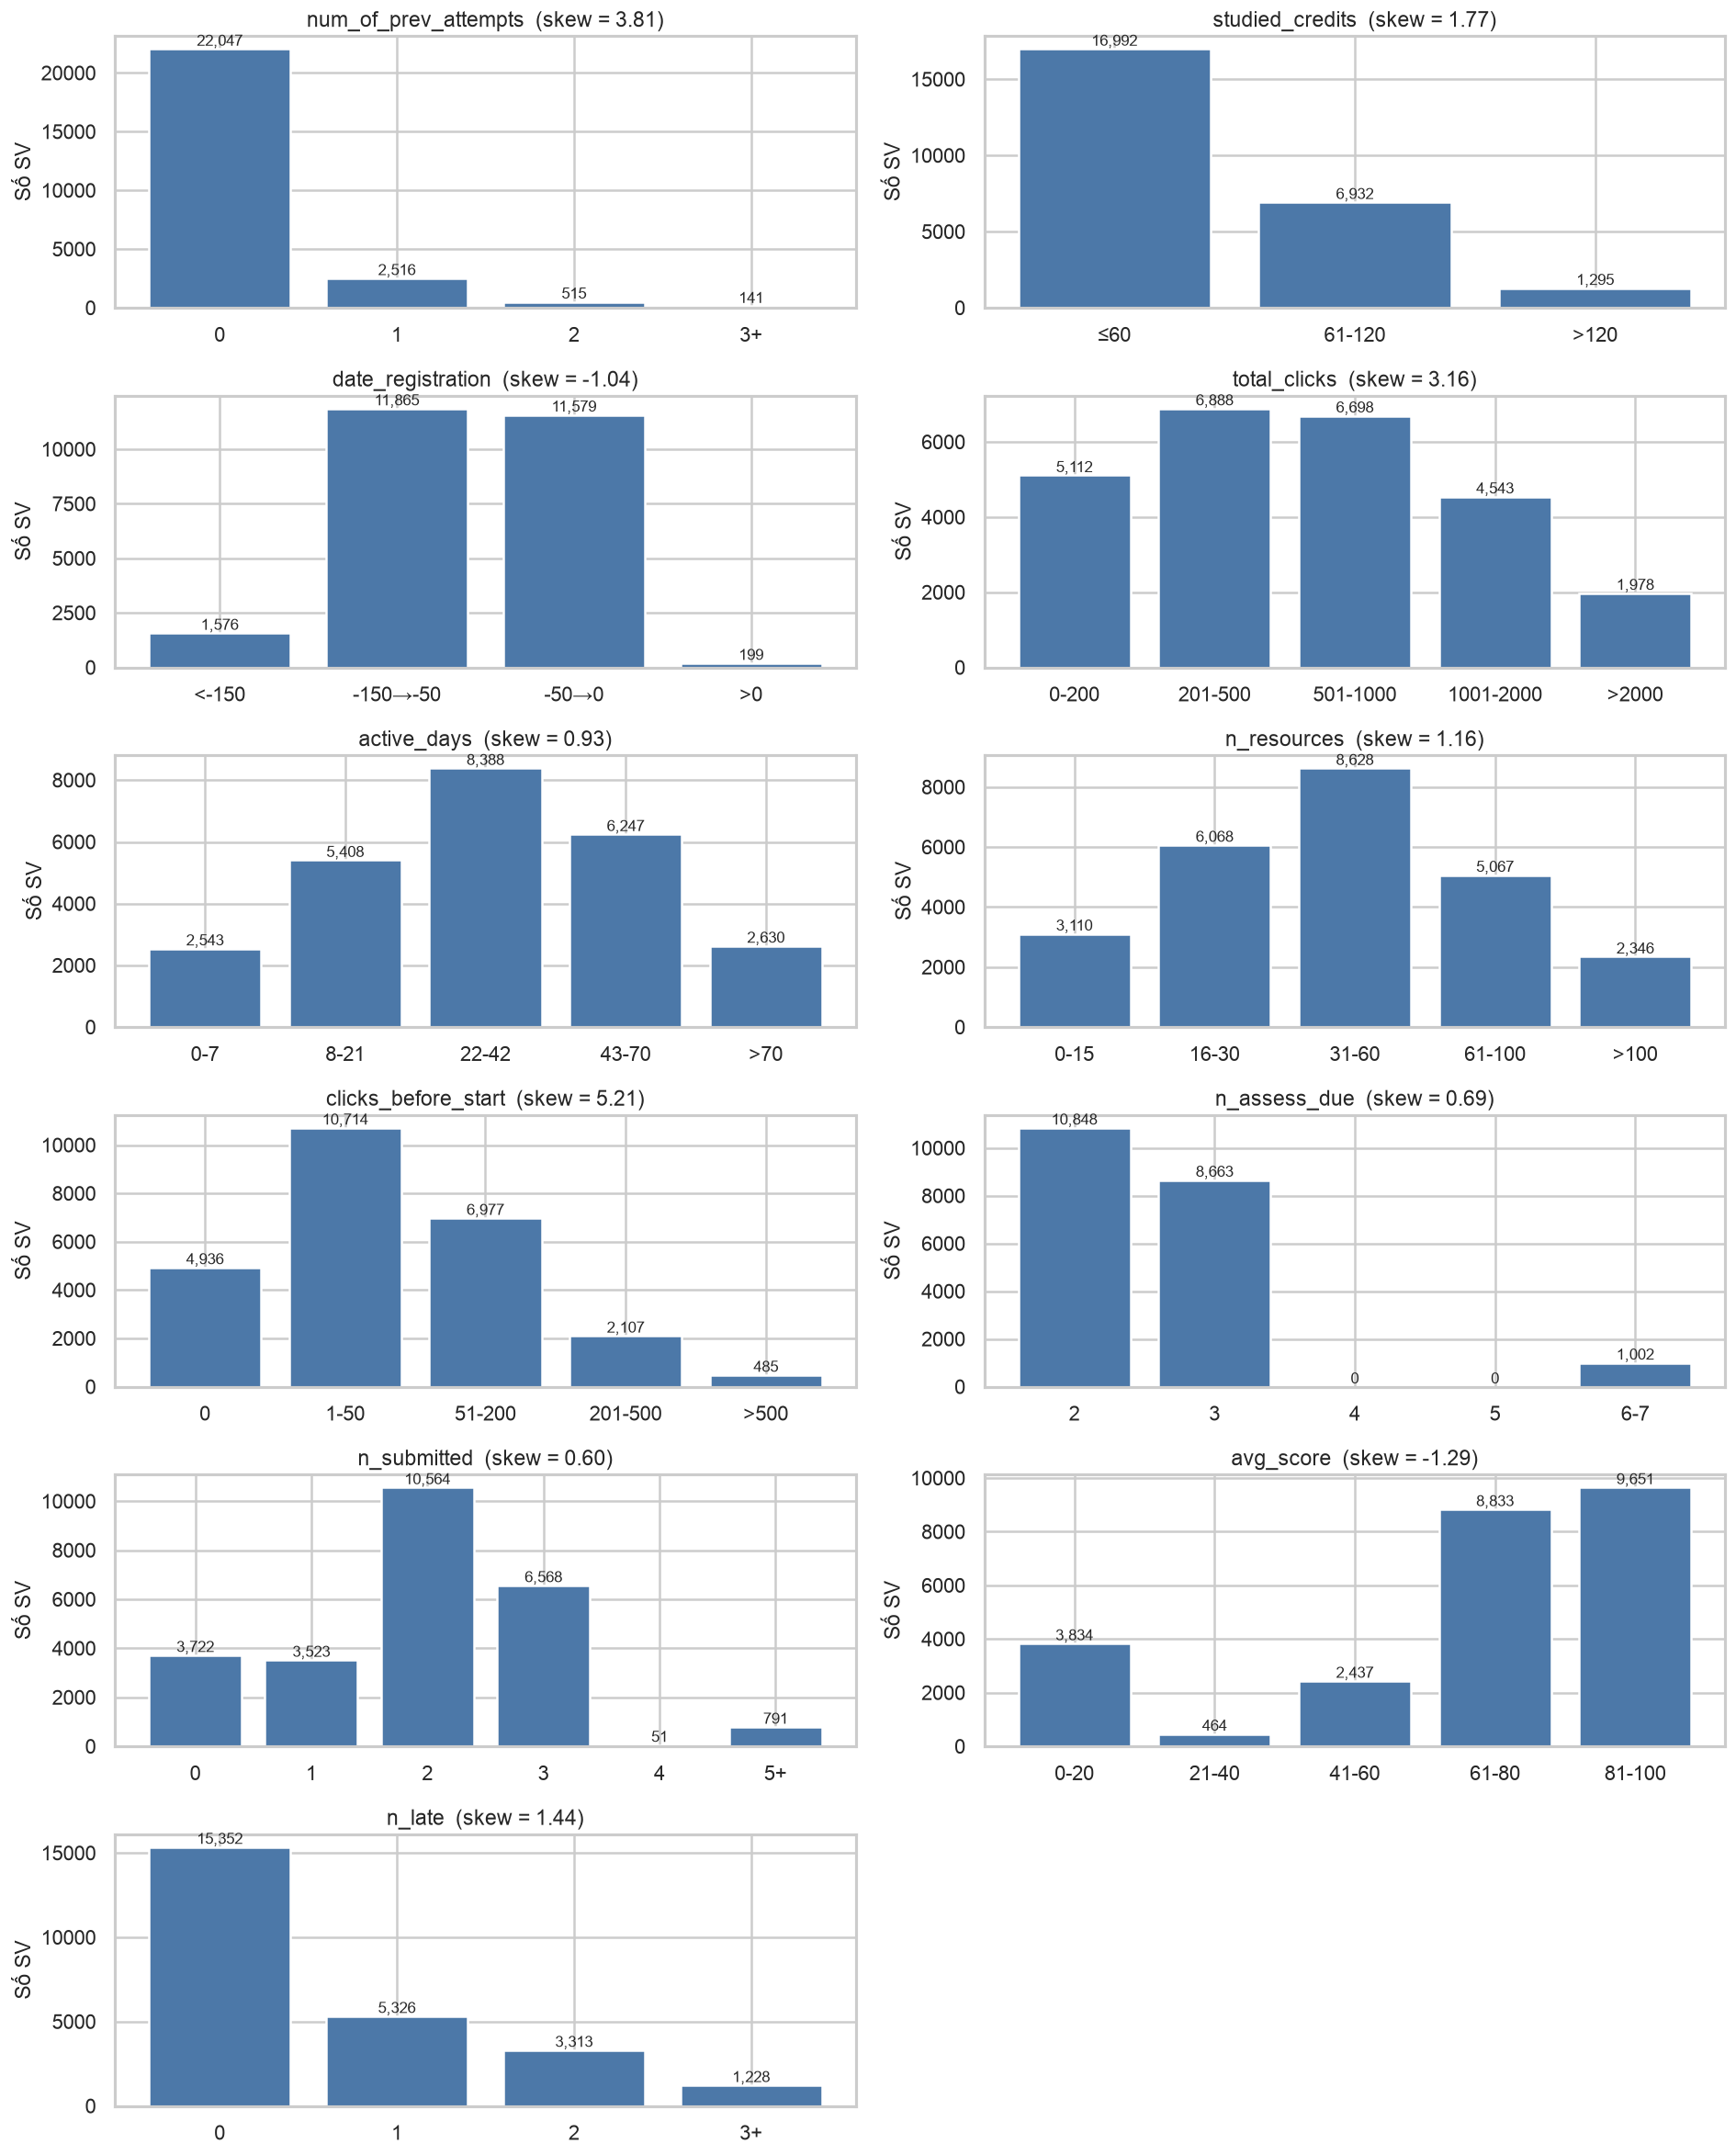

In [11]:
# Phân tích đơn biến cho 11 biến số, gộp thành interval, bar chart, skew ở tiêu đề.
specs = [
    # (tên biến, bins, labels)
    ('num_of_prev_attempts', [-0.5, 0.5, 1.5, 2.5, 6.5], ['0', '1', '2', '3+']),
    ('studied_credits',      [0, 60, 120, 700],          ['≤60', '61-120', '>120']),
    ('date_registration',    [-350, -150, -50, 0, 200],  ['<-150', '-150→-50', '-50→0', '>0']),
    ('total_clicks',         [-1, 200, 500, 1000, 2000, 13000],
                                                        ['0-200', '201-500', '501-1000', '1001-2000', '>2000']),
    ('active_days',          [-1, 7, 21, 42, 70, 200],   ['0-7', '8-21', '22-42', '43-70', '>70']),
    ('n_resources',          [-1, 15, 30, 60, 100, 350], ['0-15', '16-30', '31-60', '61-100', '>100']),
    ('clicks_before_start',  [-1, 0, 50, 200, 500, 4000],['0', '1-50', '51-200', '201-500', '>500']),
    ('n_assess_due',         [1.5, 2.5, 3.5, 4.5, 5.5, 7.5], ['2', '3', '4', '5', '6-7']),
    ('n_submitted',          [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 7.5], ['0','1','2','3','4','5+']),
    ('avg_score',            [-1, 20, 40, 60, 80, 100],  ['0-20', '21-40', '41-60', '61-80', '81-100']),
    ('n_late',               [-0.5, 0.5, 1.5, 2.5, 6.5], ['0', '1', '2', '3+']),
]

import math
nrow = math.ceil(len(specs) / 2)
fig, axes = plt.subplots(nrow, 2, figsize=(16, 3.3*nrow))
for ax, (col, bins, lbls) in zip(axes.flat, specs):
    grouped = pd.cut(df_clean[col], bins=bins, labels=lbls, include_lowest=True)
    cnt = grouped.value_counts().reindex(lbls)
    ax.bar(lbls, cnt.values, color='#4C78A8', edgecolor='white')
    for j, v in enumerate(cnt.values):
        ax.text(j, v, f'{v:,}', ha='center', va='bottom', fontsize=10)
    ax.set_title(f'{col}  (skew = {df_clean[col].skew():.2f})', fontsize=14)
    ax.set_ylabel('Số SV')
# Ô cuối trống
for ax in axes.flat[len(specs):]:
    ax.axis('off')
plt.tight_layout(); plt.show()


**Nhận xét ngắn theo từng biến:**

- `num_of_prev_attempts` skew +3.8: 86 % SV chưa học lại lần nào.
- `studied_credits` skew +1.8: phần lớn 60-120 tín chỉ, ít SV đăng ký cao bất thường.
- `date_registration` skew −1.0: đa số SV đăng ký trước khai giảng 50-150 ngày.
- `total_clicks` skew +3.2: đa số SV ≤ 1.000 click, vài SV cực chăm.
- `active_days` skew +0.9: đa số 8-42 ngày hoạt động.
- `n_resources` skew +1.2: tập trung 16-60 tài nguyên.
- `clicks_before_start` skew +5.2: phần lớn không vào VLE trước khai giảng — đuôi rất dài.
- `n_assess_due` phân bố chuẩn quanh 2-3 bài.
- `n_submitted` lệch nhẹ: SV thường nộp 0-2 bài trước mốc 40 %.
- `avg_score` skew −1.3: cụm điểm cao ở 61-100 nhưng có cụm 0-20 đáng chú ý (SV không nộp bài).
- `n_late` skew +1.4: 60 % không nộp trễ, một số SV trễ 1-3 bài.

**Vì sao cần biến đổi log cho một số biến (log1p):**

Các biến có skew > 2 (`total_clicks` +3.2, `clicks_before_start` +5.2) khiến mô hình tuyến tính như Logistic Regression bị hệ số kéo lệch bởi vài sinh viên outlier (siêu chăm). Dùng `log1p(x) = log(1 + x)` ép đuôi dài về gần tâm, giúp hệ số ổn định. Dùng `log1p` thay vì `log` vì nhiều sinh viên có 0 click — `log(0)` báo lỗi còn `log1p(0) = 0` chuẩn. Random Forest ít bị ảnh hưởng, nhưng vẫn giữ log để nhất quán feature ở Part 5.


**Dùng biến đổi logarit — dạng log(1 + x) — để chuẩn hoá các biến lệch mạnh.**

Trong thống kê, khi một biến có đuôi dài về phía phải (skew lớn hơn khoảng 1 – 2), người ta thường dùng **biến đổi logarit** (log transformation) để kéo đuôi về gần tâm, làm phân phối gần đối xứng. Công thức áp dụng ở đây là **log(1 + x)** (ký hiệu trong code là `log1p`). Thêm hằng số **+1** để xử lý được các giá trị bằng 0: `log(0)` báo lỗi, còn `log(1 + 0) = 0` vẫn hợp lệ. Trong OULAD, nhiều sinh viên có 0 click nên phải dùng dạng `log(1+x)` chứ không phải log thuần tuý.

**Kết quả cụ thể trên 3 biến click (sau khi chặn tại phân vị 99):**

| Biến | skew gốc | sau log(1+x) | sau √x | sau ∛x |
|---|---:|---:|---:|---:|
| `total_clicks` | **+1.99** | −1.80 | +0.65 | **−0.02** |
| `clicks_before_start` | **+2.76** | **−0.29** | +1.05 | +0.28 |
| `n_resources` | +0.98 | −1.51 | **+0.01** | −0.73 |

Đọc bảng: với `clicks_before_start` skew gốc 2.76, biến đổi log(1+x) đưa về −0.29 — gần đối xứng, lý tưởng. Với `total_clicks` skew gốc 1.99, log(1+x) hơi "quá liều" (ép thành lệch trái −1.80) — nếu tối ưu tuyệt đối thì căn bậc ba (∛x) tốt hơn (−0.02).

**Quyết định của báo cáo.** Dùng biến đổi log(1+x) cho cả `total_clicks` và `clicks_before_start` vì:

1. Đồng nhất tên biến phái sinh (`log_total_clicks`, `log_clicks_before_start`) — dễ đọc, dễ bảo trì code.
2. log(0+1) = 0, không cần xử lý thêm cho sinh viên 0 click.
3. Trên `total_clicks`, vẫn giảm được |skew| từ 1.99 xuống 1.80. |skew| < 2 nằm trong ngưỡng chấp nhận được cho Logistic Regression.
4. Random Forest không yêu cầu phân phối cụ thể, chỉ dùng thứ tự — biến đổi logarit không làm đổi thứ tự nên không ảnh hưởng đến cây.

Nếu cần tối ưu tuyệt đối cho Logistic Regression, có thể đổi `total_clicks` sang căn bậc ba. Chênh lệch Precision / Recall trên dataset này không đáng kể.


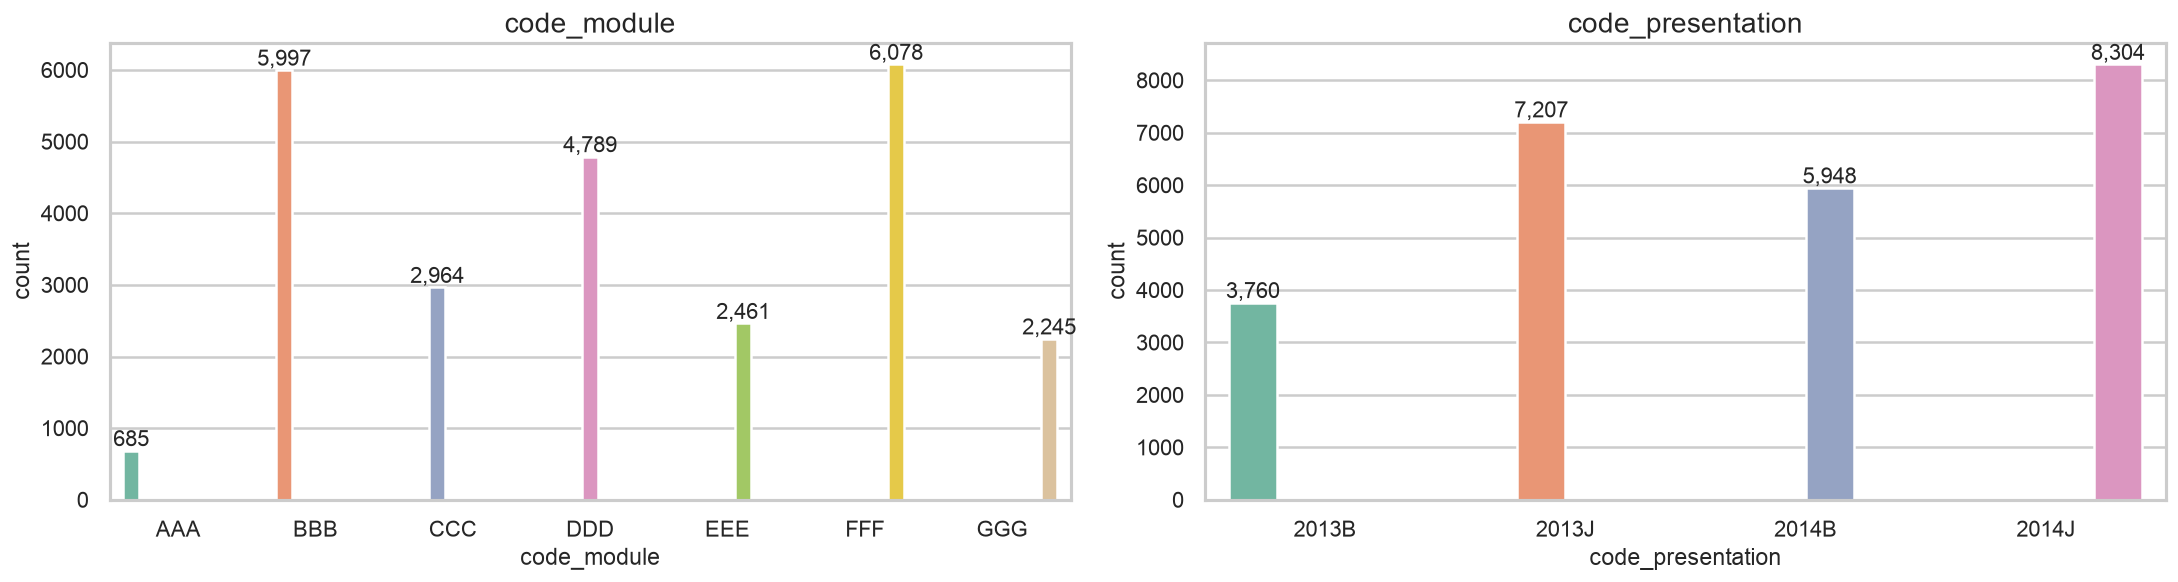

In [12]:
# Countplot biến phân loại
fig, axes = plt.subplots(1, 2, figsize=(18.4, 5.1))
for ax, c in zip(axes, ['code_module','code_presentation']):
    order = sorted(df_clean[c].unique())
    sns.countplot(x=c, data=df_clean, ax=ax, order=order,
                  hue=c, palette='Set2', legend=False)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height()):,}',
                    (p.get_x()+p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=13)
    ax.set_title(f'{c}')
plt.tight_layout(); plt.show()


**Nhận xét.** `code_module` không đồng đều (FFF/BBB nhiều, AAA ít) → đưa vào model như biến điều khiển. 4 kỳ phân bố cân → **chia theo thời gian (temporal split) train=3 kỳ đầu, test=2014J** là đúng.


### 3.5 Xử lý outlier (Boxplot + IQR)

quy tắc khoảng tứ phân vị (IQR) để phát hiện: $\text{Low} = Q_1 - 1.5\,\text{IQR}$, $\text{High} = Q_3 + 1.5\,\text{IQR}$. Xử lý: capping tại P99 cho biến click, giữ nguyên biến có đuôi mang tín hiệu.


In [13]:
# Boxplot để nhìn trực quan vị trí outlier: 2 biểu đồ mỗi dòng cho dễ đọc.
# Bỏ num_of_prev_attempts khỏi grid này vì biến rời rạc 0-6 không hợp boxplot,
# sẽ xem ở phần phân tích đơn biến bằng countplot.
num_cont = ['studied_credits', 'date_registration',
            'total_clicks', 'active_days', 'n_resources', 'clicks_before_start',
            'n_assess_due', 'n_submitted', 'avg_score', 'n_late']

rows = []
for c in num_cont:
    s = df_clean[c]
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((s < low) | (s > high)).sum()
    rows.append({'bien': c, 'min': s.min(), 'median': s.median(), 'max': s.max(),
                 'IQR_high': round(high, 1), 'n_outlier': n_out,
                 'pct_out': round(n_out/len(s)*100, 1)})
pd.DataFrame(rows)


,bien,min,median,max,IQR_high,n_outlier,pct_out
0,studied_credits,30.0,60.0,630.0,135.0,1244,4.9
1,date_registration,-311.0,-52.0,81.0,70.0,313,1.2
2,total_clicks,0.0,535.0,12920.0,2194.0,1619,6.4
3,active_days,0.0,33.0,239.0,100.5,435,1.7
4,n_resources,0.0,40.0,313.0,129.0,723,2.9
5,clicks_before_start,0.0,28.0,3731.0,223.0,2230,8.8
6,n_assess_due,0.0,2.0,6.0,4.5,3247,12.9
7,n_submitted,0.0,2.0,6.0,6.0,0,0.0
8,avg_score,0.0,75.5,100.0,125.6,3813,15.1
9,n_late,0.0,0.0,6.0,2.5,1228,4.9


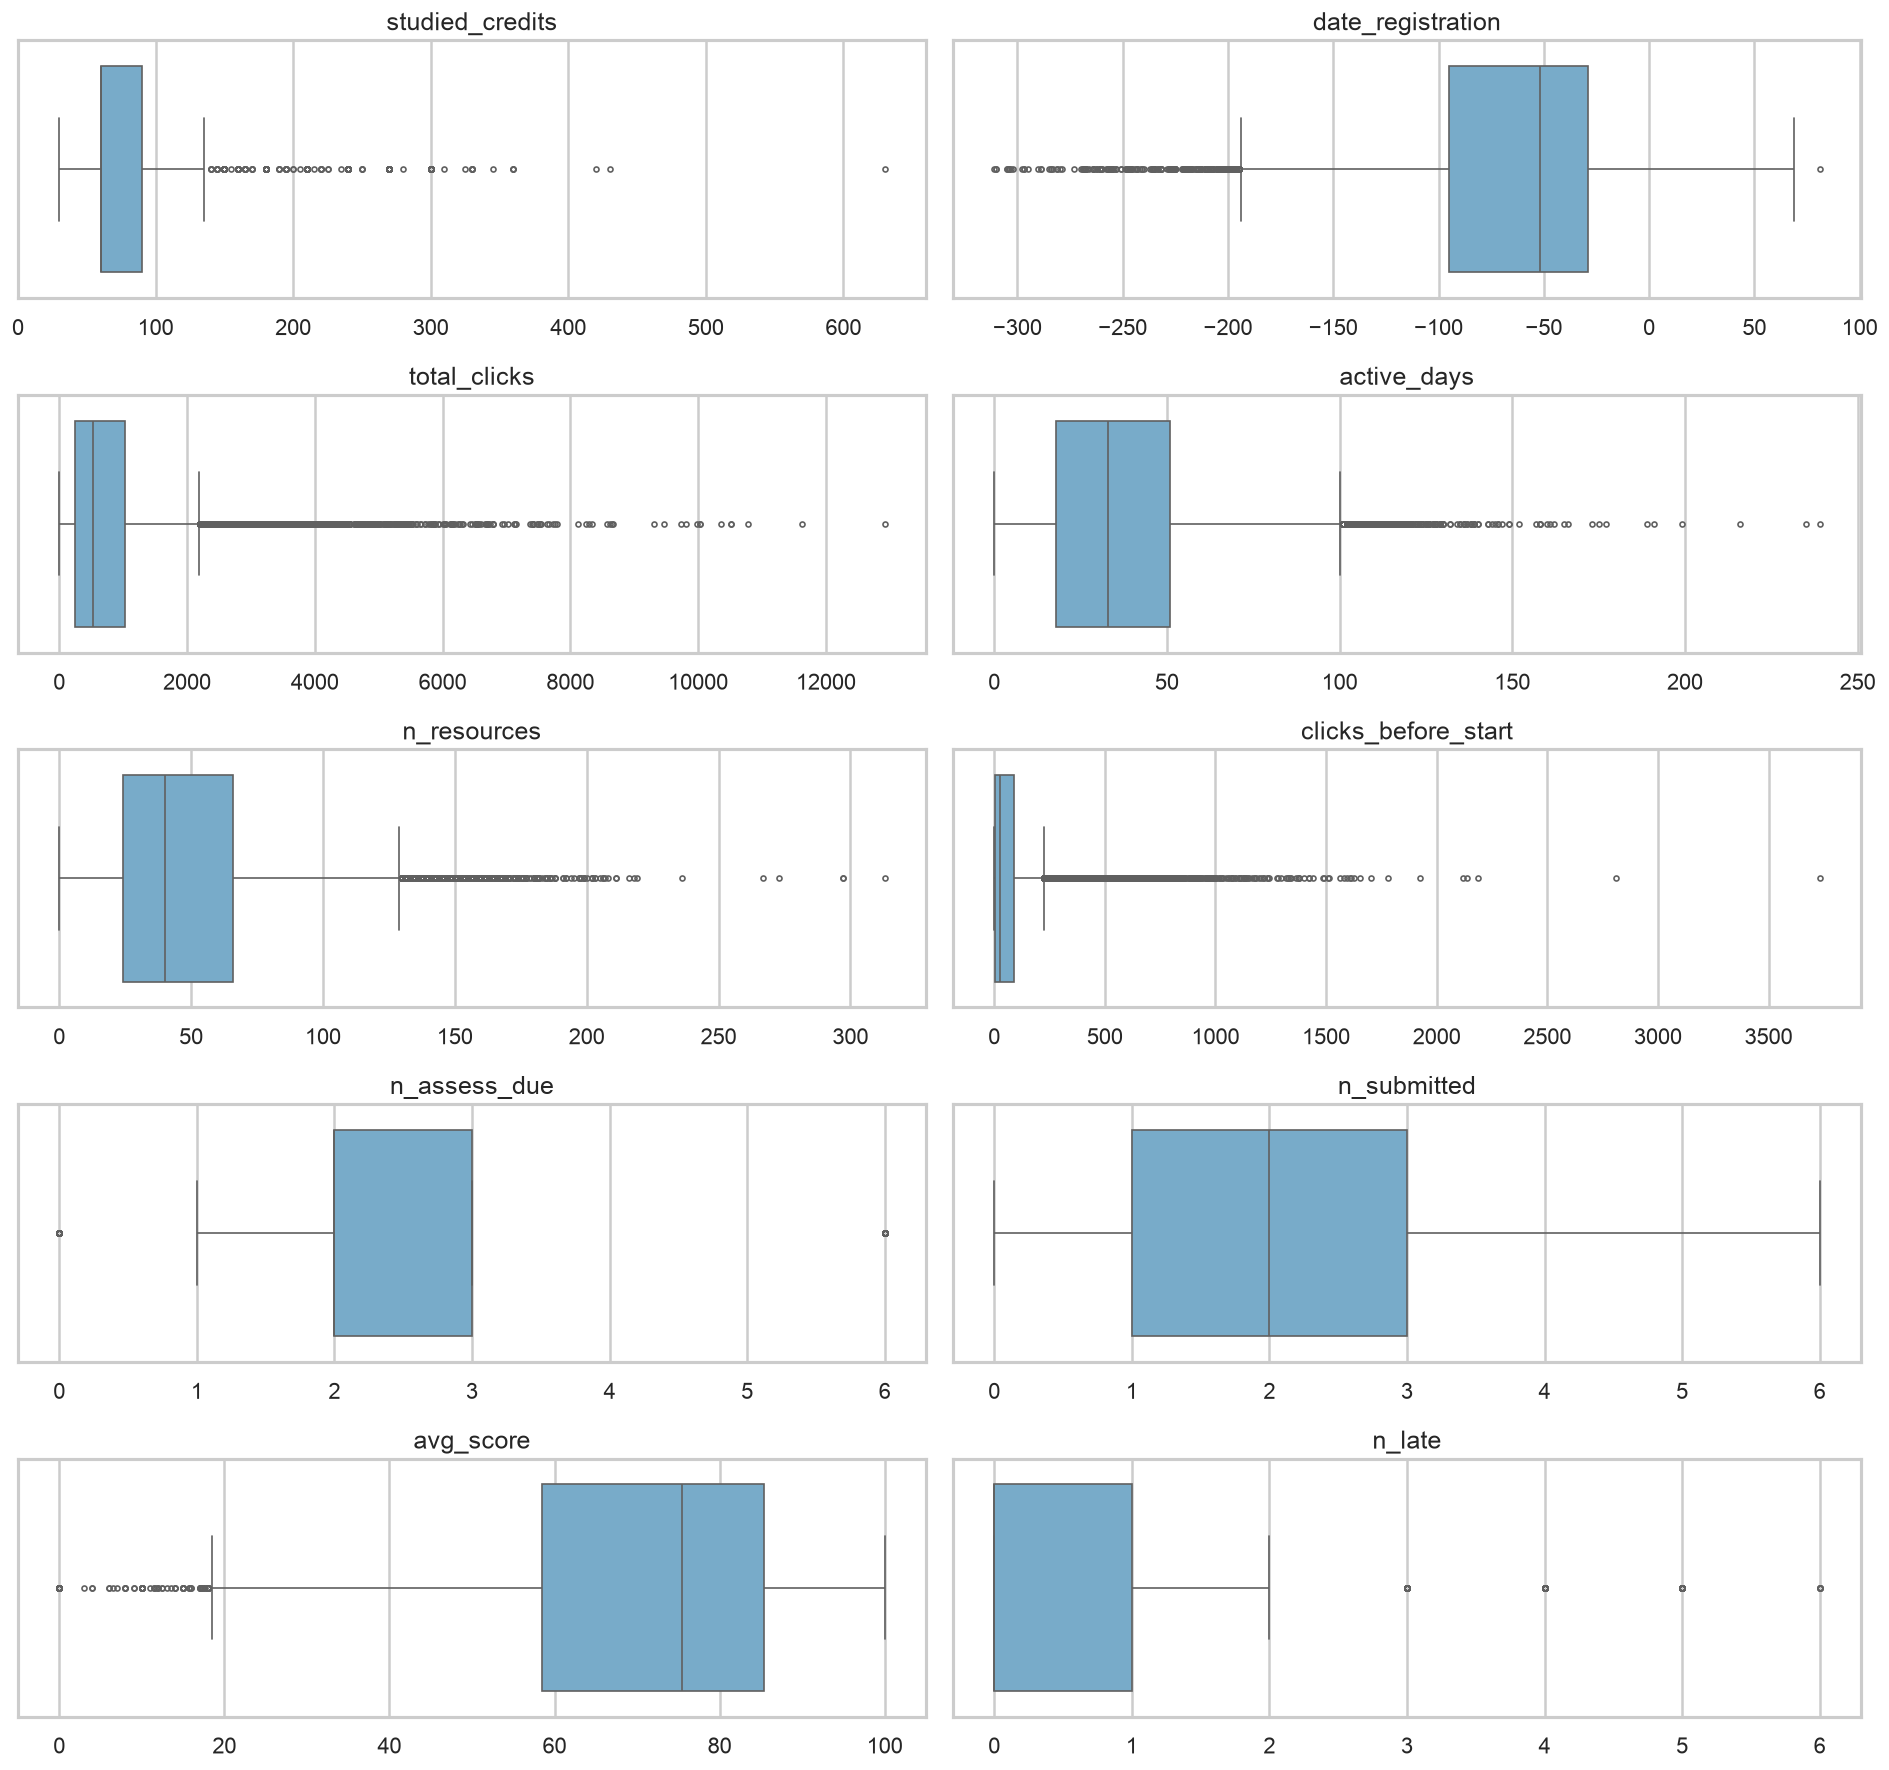

In [14]:
import math
ncol = 2; nrow = math.ceil(len(num_cont)/ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.0*nrow))
for ax, c in zip(axes.flat, num_cont):
    sns.boxplot(x=df_clean[c], ax=ax, color='#6BAED6', fliersize=3)
    ax.set_title(c, fontsize=15)
    ax.set_xlabel('')
for ax in axes.flat[len(num_cont):]:
    ax.axis('off')
plt.tight_layout(); plt.show()


**Phân bố và quyết định xử lý từng biến:**

| Biến | Hình dạng phân bố | Xử lý | Vì sao |
|---|---|---|---|
| `total_clicks`, `active_days`, `n_resources`, `clicks_before_start` | Đuôi phải dài (độ lệch (skew) 3.16 – 5.21) | Chặn tại phân vị 99 (P99) | Giá trị cực cao là sinh viên siêu chăm, không phải lỗi; cap chặn đuôi nhưng giữ dòng. |
| `avg_score` | Đuôi trái, cụm tại 0 điểm | Giữ nguyên | Điểm thấp = tín hiệu nguy cơ (at_risk > 80 % ở nhóm điểm < 20); cap làm mô hình bỏ sót. |
| `studied_credits` | Rời rạc 30 / 60 / 90 / 120 + đuôi phải | Giữ nguyên | Giá trị cao có thể là sinh viên học song ngành, không phải lỗi dữ liệu. |
| `num_of_prev_attempts` | Rời rạc 0 – 6, chủ yếu là 0 | Chuyển thành `is_repeater` (0/1) ở phần tạo biến | Chi tiết số lần ít dùng cho mô hình, chỉ cần "có / không học lại". |
| `date_registration` | Đuôi trái | Giữ nguyên | Giá trị âm = đăng ký trước ngày khai giảng, nghĩa là có kế hoạch, không phải lỗi. |
| `n_submitted`, `n_late`, `n_assess_due` | Rời rạc 0 – 7 | Giữ nguyên | Đã trong khoảng hẹp, không cần xử lý. |

**Outlier ảnh hưởng độ chính xác như thế nào — nói thẳng bằng số:**

Biến `total_clicks` có max = 12.940 clicks trong khi mean ≈ 630 và std ≈ 800. Nếu giữ nguyên rồi đưa vào `chuẩn hoá biến (StandardScaler)` (chuẩn hoá trung bình 0, độ lệch 1), giá trị cao nhất có **z-score ≈ 15** trong khi 99 % sinh viên nằm trong khoảng z-score từ −0.8 đến +2. Khi đưa vào Logistic Regression, hệ số của biến này bị vài sinh viên outlier kéo lệch: để không khớp quá mức vào 1 % outlier, mô hình buộc phải giảm trị tuyệt đối hệ số, nghĩa là **mất khả năng phân biệt cho 99 % sinh viên còn lại** và Recall, Precision cùng giảm.

Random Forest ít bị ảnh hưởng về hiệu năng nhưng vẫn gặp vấn đề khác: các split tại đuôi phải chỉ tách được vài trăm sinh viên trên đỉnh nên gain nhỏ, còn các split ở vùng tâm (nơi cần phân biệt nhất) lại bị lấn át, kết quả là độ quan trọng biến (feature importance) bị đánh giá lệch.

**So sánh phương án xử lý đuôi (trên tập 25.219 dòng):**

| Phương án | `total_clicks` | `clicks_before_start` | `n_resources` | `studied_credits` |
|---|---:|---:|---:|---:|
| cắt theo khoảng tứ phân vị IQR (loại dòng > Q3 + 1.5·IQR) | loại **1.619** dòng (6.4 %) | loại **2.230** dòng (8.8 %) | loại **723** (2.9 %) | loại **1.244** (4.9 %) |
| Chặn tại phân vị 99 (P99) (giữ dòng, thay bằng P99) | thay **253** dòng (1.0 %) | thay **253** dòng (1.0 %) | thay **251** (1.0 %) | thay **252** (1.0 %) |

IQR sẽ cắt tới **2.230 sinh viên** khỏi `clicks_before_start`, phần lớn là sinh viên siêu chăm (at_risk thấp) — tức là mất một nguồn tín hiệu tốt. Cap P99 chỉ thay 1 % giá trị cao nhất bằng chính ngưỡng P99 nên phân phối tâm vẫn ổn định mà không mất dòng nào. Z-score không phù hợp vì các biến đếm này cực lệch, không gần phân phối chuẩn.


In [15]:
# Kiểm chứng: SV ở top 1% total_clicks có at_risk CAO hay THẤP?
# Nếu THẤP → outlier là tín hiệu tích cực → giữ dòng, chỉ cap đuôi là đúng.
high_click = df_clean['total_clicks'] >= df_clean['total_clicks'].quantile(.99)
low_score  = df_clean['avg_score']    <= df_clean['avg_score'].quantile(.10)
print(f'SV top 1% total_clicks → at_risk = {df_clean[high_click]["at_risk"].mean():.3f} '
      f'(toàn mẫu: {df_clean["at_risk"].mean():.3f})')
print(f'SV bottom 10% avg_score → at_risk = {df_clean[low_score]["at_risk"].mean():.3f}')


SV top 1% total_clicks → at_risk = 0.107 (toàn mẫu: 0.390)
SV bottom 10% avg_score → at_risk = 0.590


**Nhận xét.** Nếu top 1% click có at_risk thấp (nhóm chăm) và bottom score có at_risk cao (nhóm thực sự nguy cơ) → logic cap/không-cap là đúng.


In [16]:
# Áp dụng Capping P99 CHỈ cho 4 biến click
cap_cols = ['total_clicks','n_resources','clicks_before_start','active_days']
before = df_clean[cap_cols].agg(['max','mean','std']).round(1)

for c in cap_cols:
    p99 = df_clean[c].quantile(.99)
    df_clean[c] = df_clean[c].clip(upper=p99)

after = df_clean[cap_cols].agg(['max','mean','std']).round(1)
print('--- Trước / Sau capping P99 ---')
compare = pd.concat([before, after], keys=['before','after'], axis=0)
print(compare)


--- Trước / Sau capping P99 ---
             total_clicks  n_resources  clicks_before_start  active_days
before max        12920.0        313.0               3731.0        239.0
       mean         795.9         48.6                 76.9         36.6
       std          883.2         34.2                139.1         25.1
after  max         4210.0        149.0                656.6        108.0
       mean         780.8         48.4                 73.8         36.5
       std          794.0         33.4                116.8         24.5


### 3.6 Export df_clean

Cột `final_result` được giữ cho mục đích audit/EDA nhưng **sẽ loại khi tạo matrix X** ở Part 5 (rò rỉ thông tin tương lai trực tiếp).


In [17]:
clean_path = G6 / 'cleaned_dataset.csv'
df_clean.to_csv(clean_path, index=False)
print(f'df_clean export: {clean_path}  shape={df_clean.shape}')
print(f'Cột flag mới: dropout_no_activity, active_but_no_submission, pending_grade, pres_year, pres_semester')


df_clean export: cleaned_dataset.csv  shape=(25219, 22)
Cột flag mới: dropout_no_activity, active_but_no_submission, pending_grade, pres_year, pres_semester


# PART 4: EDA & FEATURE ENGINEERING


### 4.1 Phân tích 2 biến (biến X và target `at_risk`)

Boxplot chia theo nhóm `at_risk = 0` (an toàn, màu xanh) và `at_risk = 1` (nguy cơ, màu đỏ). Nếu hai hộp lệch nhau rõ (median cách xa nhau) thì biến đó có sức dự báo mạnh — khi biết giá trị biến này là biết nhóm SV thuộc an toàn hay nguy cơ.

Chỉ số đo nhanh: **Δmed = median(an toàn) − median(nguy cơ)**. Δmed càng lớn (dương hoặc âm) → biến càng mạnh. Δmed ≈ 0 → biến không phân biệt được 2 nhóm.


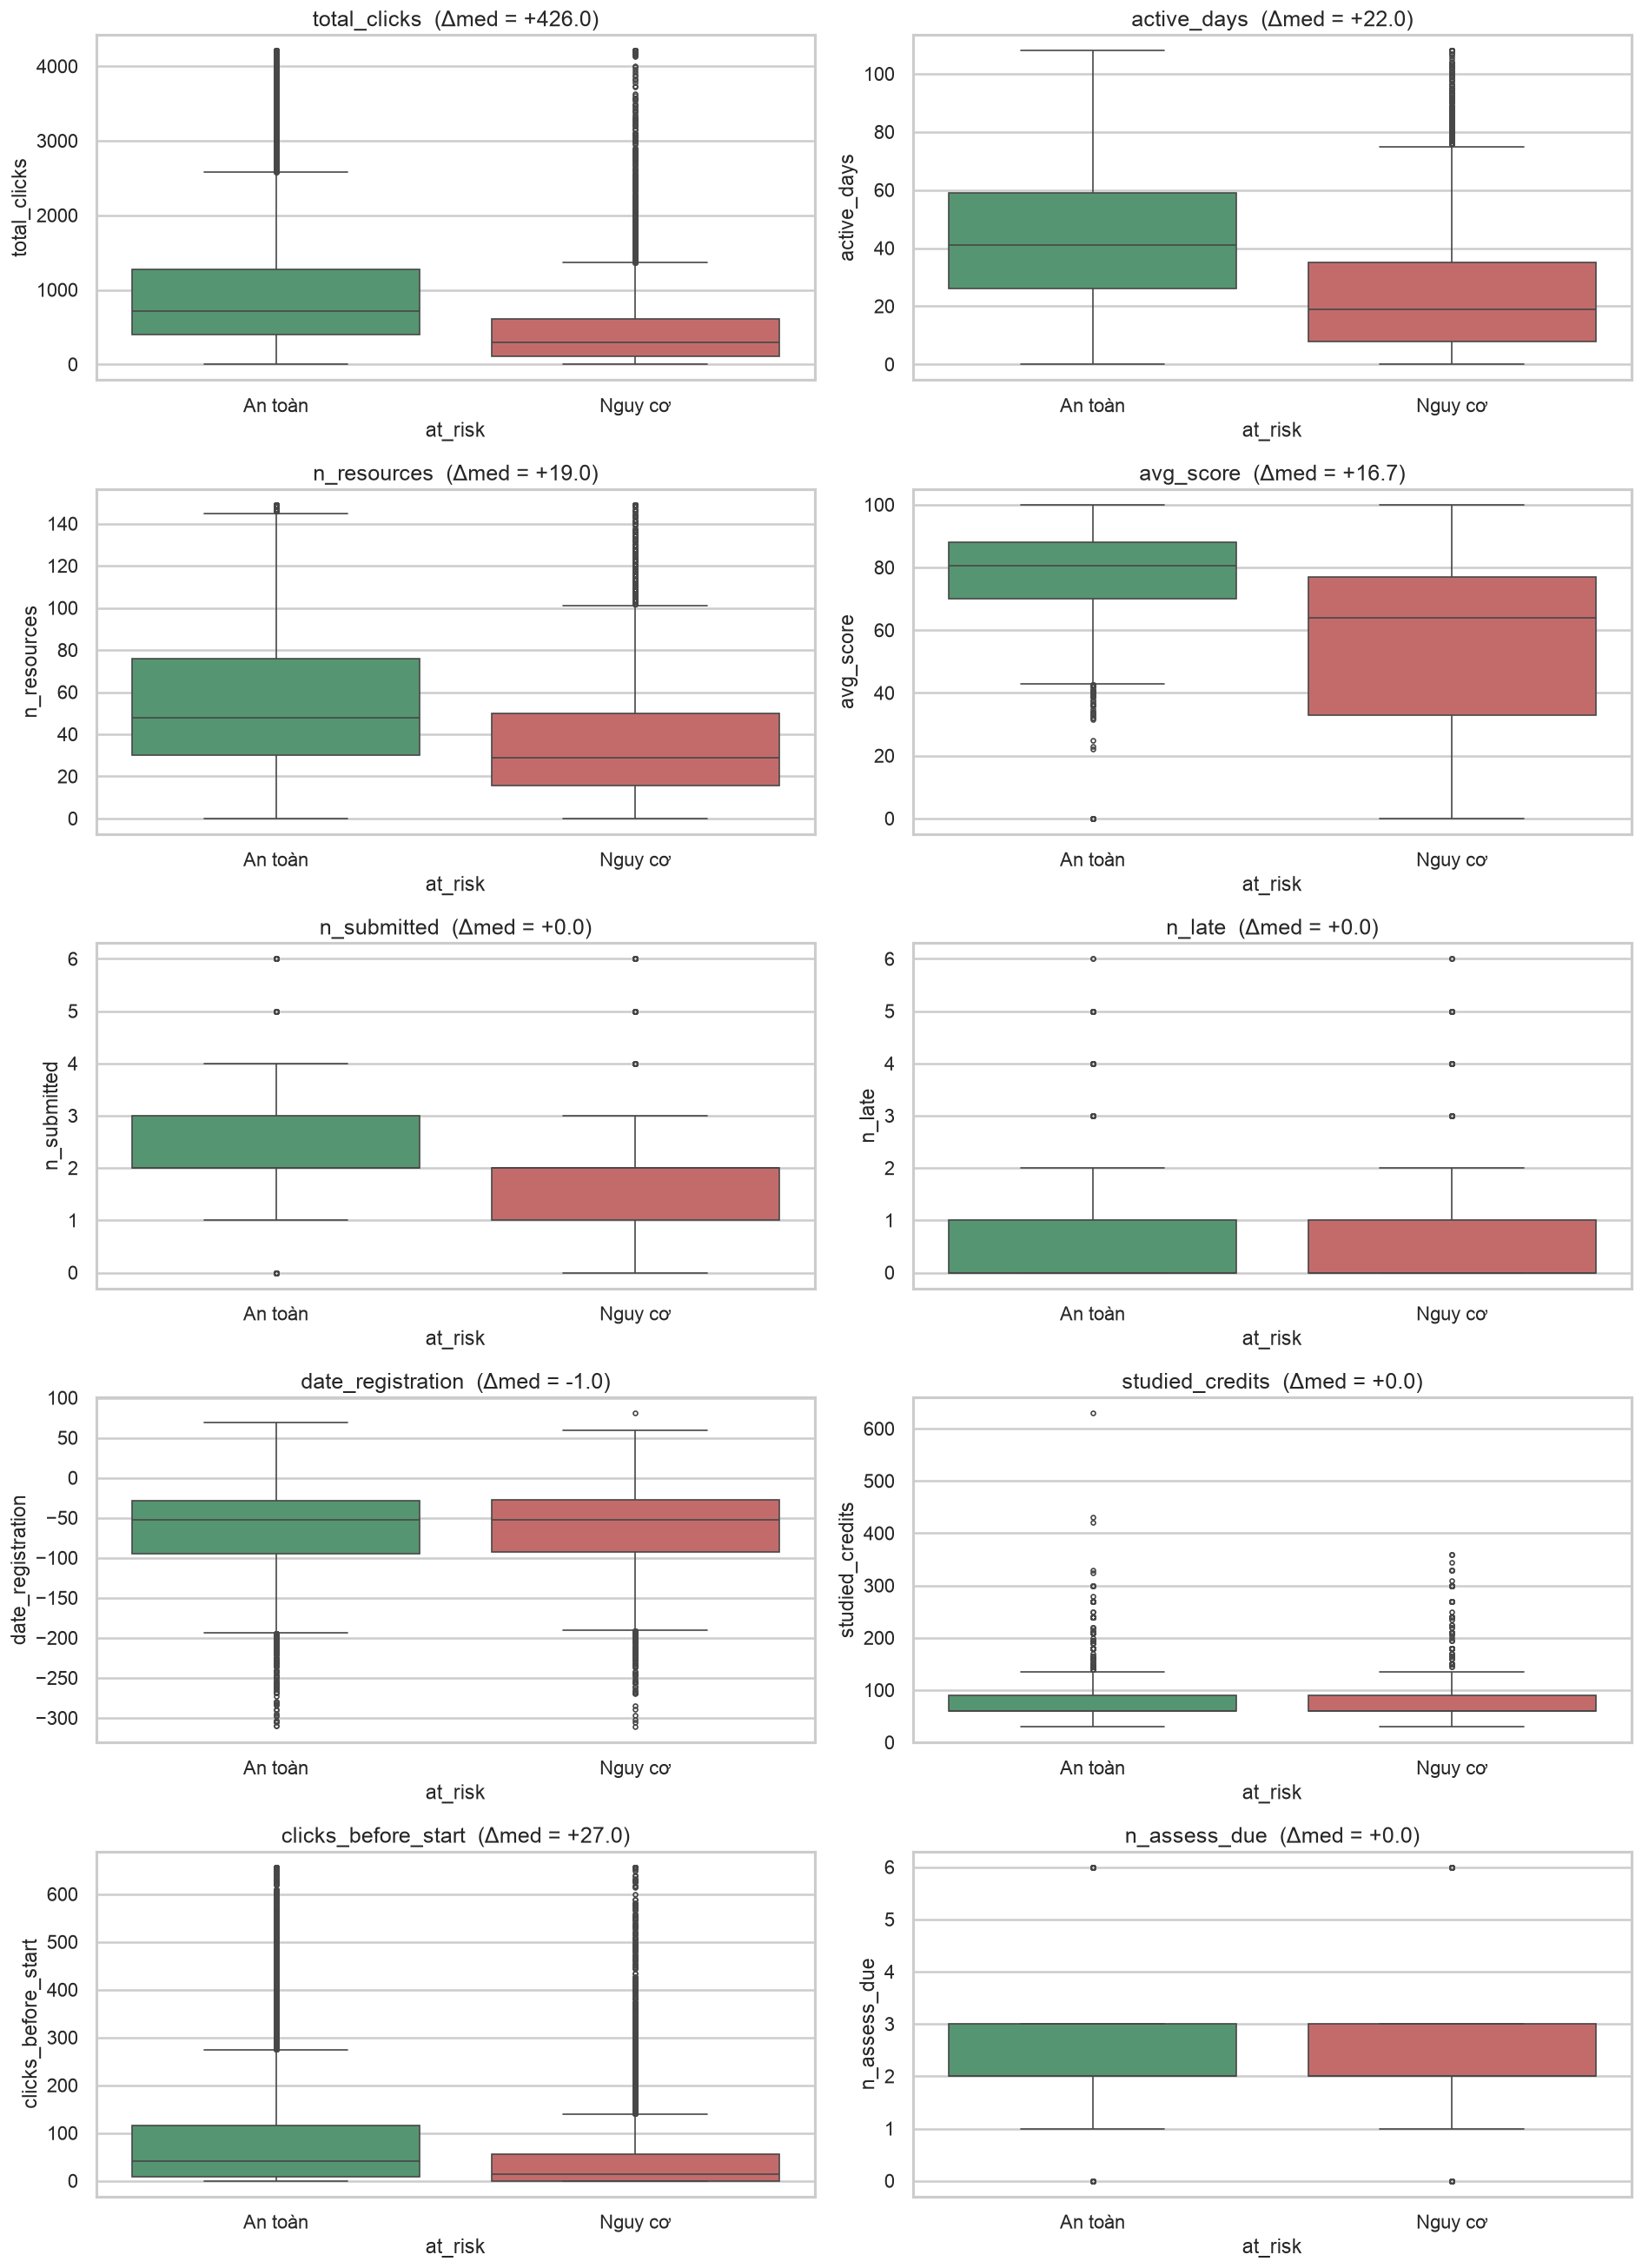

In [18]:
# Boxplot chia theo at_risk: khoảng cách median càng lớn → feature càng mạnh.
num_bi = ['total_clicks', 'active_days', 'n_resources', 'avg_score',
          'n_submitted', 'n_late', 'date_registration', 'studied_credits',
          'clicks_before_start', 'n_assess_due']
fig, axes = plt.subplots(5, 2, figsize=(16, 22))
for ax, c in zip(axes.flat, num_bi):
    sns.boxplot(data=df_clean, x='at_risk', y=c, ax=ax,
                hue='at_risk', palette={0:'#4C9F70', 1:'#D25C5C'},
                legend=False, fliersize=3)
    med0 = df_clean[df_clean['at_risk']==0][c].median()
    med1 = df_clean[df_clean['at_risk']==1][c].median()
    ax.set_title(f'{c}  (Δmed = {med0-med1:+.1f})', fontsize=15)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['An toàn', 'Nguy cơ'])
plt.tight_layout(); plt.show()


**Nhận xét bivariate — biến nào thực sự phân biệt được nguy cơ (số thực):**

| Biến | Median an toàn | Median nguy cơ | Δmed | Sức dự báo |
|---|---:|---:|---:|---|
| `total_clicks` | 716 | 290 | **+426** | **Rất mạnh** — SV nguy cơ click ít hơn 2.5 lần |
| `clicks_before_start` | 41 | 14 | **+27** | **Rất mạnh** — SV an toàn chủ động vào VLE trước khai giảng |
| `active_days` | 41 | 19 | **+22** | **Mạnh** — SV an toàn hoạt động nhiều hơn 2 lần |
| `n_resources` | 48 | 29 | +19 | Mạnh — SV an toàn mở nhiều tài nguyên hơn |
| `avg_score` | 80.7 | 64.0 | +16.7 | Mạnh — cách nhau 17 điểm (rất đáng kể trên thang 100) |
| `n_submitted` | 2 | 2 | 0 | **Yếu** — số lượng giống nhau, chỉ khác ở chất lượng |
| `n_assess_due` | 2 | 2 | 0 | **Yếu** — thuộc tính lớp, giống nhau cho mọi SV cùng lớp |
| `n_late` | 0 | 0 | 0 | **Yếu** — median cùng = 0 nhưng phân bố khác (xem đuôi) |
| `studied_credits` | 60 | 60 | 0 | **Yếu** — median giống nhau |
| `date_registration` | −53 | −52 | −1 | **Rất yếu** — gần như không phân biệt |

**Kết luận.** Nhóm biến **click & hoạt động VLE** (`total_clicks`, `active_days`, `n_resources`, `clicks_before_start`) + **điểm đã đạt** (`avg_score`) là 5 biến dự báo mạnh nhất. 5 biến còn lại (số bài nộp, trễ hạn, tín chỉ, ngày đăng ký) có Δmed nhỏ nhưng **không loại bỏ hẳn** — chúng có thể mang thông tin bổ sung khi kết hợp với biến khác (xem phần tạo biến mới ở 4.4).

Biểu đồ còn gợi ý một điều quan trọng: **đuôi của biến cũng khác nhau**. SV nguy cơ có nhiều SV ở đáy (ví dụ `total_clicks` gần 0), còn SV an toàn tập trung cao hơn. Chính đuôi phía dưới là nơi mô hình học được "thế nào là đang bỏ bê lớp".


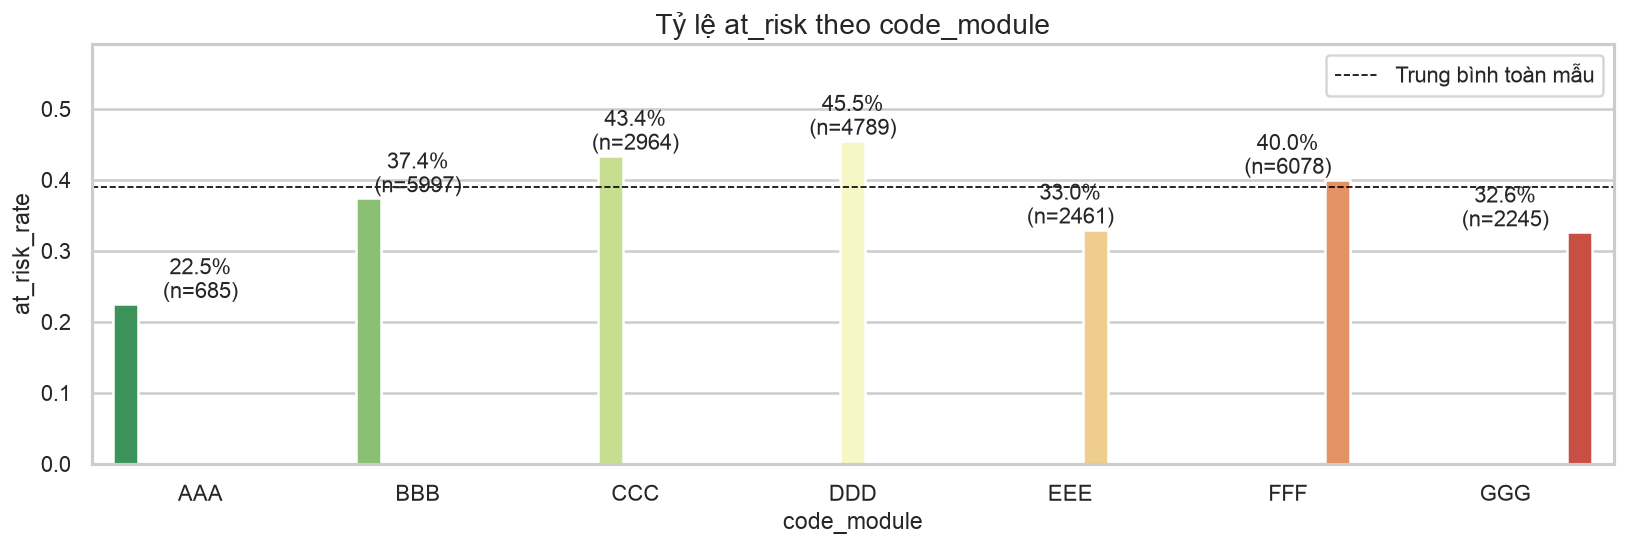

In [19]:
# At_risk rate theo code_module
rate_mod = df_clean.groupby('code_module')['at_risk'].agg(['mean','count']).round(3)
rate_mod.columns = ['at_risk_rate','n']
fig, ax = plt.subplots(figsize=(13.8, 4.8))
sns.barplot(x=rate_mod.index, y=rate_mod['at_risk_rate'], ax=ax,
            hue=rate_mod.index, palette='RdYlGn_r', legend=False)
for i, (v, n) in enumerate(zip(rate_mod['at_risk_rate'], rate_mod['n'])):
    ax.text(i, v, f'{v:.1%}\n(n={n})', ha='center', va='bottom', fontsize=13)
ax.axhline(df_clean['at_risk'].mean(), color='black', ls='--', lw=1, label='Trung bình toàn mẫu')
ax.set_title('Tỷ lệ at_risk theo code_module')
ax.set_ylim(0, rate_mod['at_risk_rate'].max()*1.3)
ax.legend(); plt.tight_layout(); plt.show()


**Nhận xét theo khoá học (số thực):**

| code_module | at_risk rate | Số SV | Nhận xét |
|---|---:|---:|---|
| **AAA** | **22.5 %** | 685 | Thấp nhất — khoá dễ qua hoặc SV chọn lọc. |
| EEE | 33.0 % | 2.461 | Thấp hơn trung bình. |
| GGG | 32.6 % | 2.245 | Thấp hơn trung bình. |
| BBB | 37.4 % | 5.997 | Gần trung bình. |
| FFF | 40.0 % | 6.078 | Xấp xỉ trung bình (39 %). |
| CCC | **43.4 %** | 2.964 | Cao hơn trung bình. |
| **DDD** | **45.5 %** | 4.789 | **Cao nhất — khoá khó nhất** hoặc SV đăng ký có xu hướng rủi ro. |

Chênh lệch giữa AAA (22.5 %) và DDD (45.5 %) là **gấp đôi** — tức là chính khoá học đã tạo ra 23 điểm phần trăm rủi ro. `code_module` phải vào mô hình bằng one-hot encoding, không được bỏ. Nếu bỏ, mô hình sẽ gán nhầm rủi ro "khoá" sang các biến khác (ví dụ `total_clicks`).


### 4.2 Phân tích đa biến (Correlation)

Mục đích phần này — nhìn một lúc toàn bộ cặp biến để trả lời 2 câu:
1. Biến nào có tương quan mạnh nhất với target `at_risk`.
2. Có cặp biến nào tương quan quá cao với nhau không — nếu có, đưa cả hai vào mô hình sẽ gây **đa cộng tuyến** (biến này có thể dự đoán được biến kia bằng quan hệ gần như tuyến tính, nên hai biến đóng góp thông tin trùng lặp).

**Spearman:** đo mức độ tỉ lệ thuận hay tỉ lệ nghịch giữa hai biến. Cách tính: sắp xếp các giá trị thành thứ hạng (rank), ví dụ sinh viên click nhiều nhất là hạng 1, ít nhất là hạng cuối. So sánh thứ hạng của hai biến — nếu SV có hạng cao ở `total_clicks` cũng có hạng cao ở `active_days` thì ρ dương (tỉ lệ thuận), ngược lại ρ âm (tỉ lệ nghịch).

**Vì sao chọn Spearman thay vì Pearson.** Pearson đo quan hệ tuyến tính thuần tuý và bị vài giá trị cực đoan kéo lệch. Dữ liệu ta có nhiều biến lệch mạnh, Pearson không đáng tin. Spearman tính trên thứ hạng nên không bị outlier ảnh hưởng — chỉ cần quan hệ đơn điệu (tỉ lệ thuận hoặc nghịch) là đo được, không yêu cầu quan hệ tuyến tính.

Giá trị ρ (rho) nằm trong [−1, +1]. ρ = 0 là không tương quan, càng xa 0 càng mạnh. |ρ| ≥ 0.8 là ngưỡng cảnh báo đa cộng tuyến.


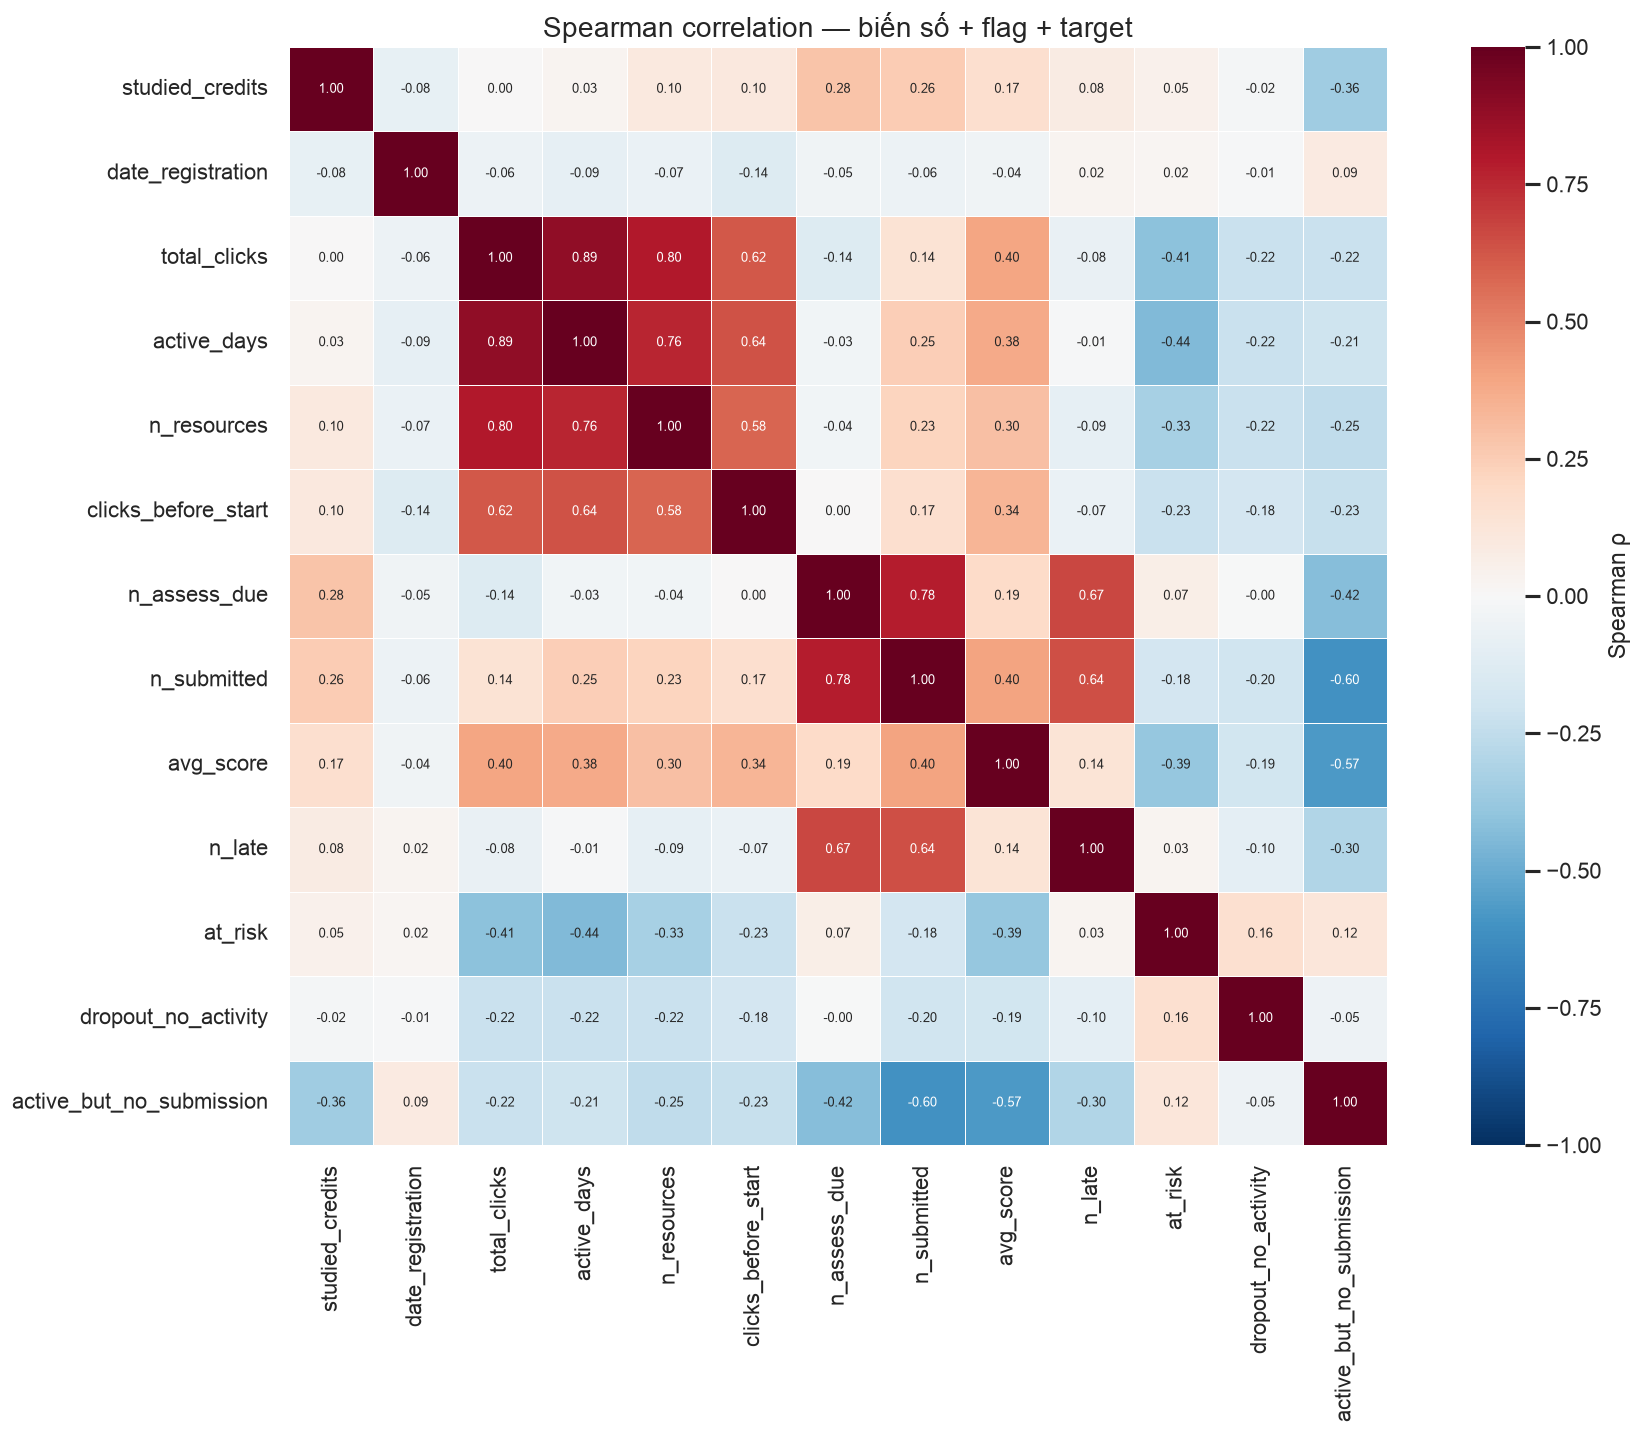

In [20]:
corr_cols = num_cont + ['at_risk','dropout_no_activity','active_but_no_submission']
corr = df_clean[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(16.1, 12.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={'label':'Spearman ρ'},
            ax=ax, annot_kws={'size':8})
ax.set_title('Spearman correlation — biến số + flag + target')
plt.tight_layout(); plt.show()


In [21]:
# Top correlation với target
corr_target = corr['at_risk'].drop('at_risk').sort_values()
print('--- Tương quan Spearman với at_risk ---')
print(corr_target.round(3))

# Cặp biến có dấu hiệu đa cộng tuyến (loại at_risk)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
mc = upper.stack().reset_index()
mc.columns = ['var1','var2','rho']
mc = mc[mc['var1'].ne('at_risk') & mc['var2'].ne('at_risk')]
mc = mc[mc['rho'].abs() >= 0.7].sort_values('rho', key=abs, ascending=False)
print('\n--- Cặp 2 biến đa cộng tuyến |ρ| >= 0.7 ---')
print(mc.round(3))


--- Tương quan Spearman với at_risk ---
active_days                -0.438
total_clicks               -0.411
avg_score                  -0.385
n_resources                -0.328
clicks_before_start        -0.225
n_submitted                -0.180
date_registration           0.023
n_late                      0.028
studied_credits             0.054
n_assess_due                0.070
active_but_no_submission    0.117
dropout_no_activity         0.159
Name: at_risk, dtype: float64

--- Cặp 2 biến đo cùng một thứ |ρ| >= 0.7 ---
            var1         var2    rho
29  total_clicks  active_days  0.888
30  total_clicks  n_resources  0.803
85  n_assess_due  n_submitted  0.782
43   active_days  n_resources  0.764


**Nhận xét heatmap.**

**Biến có tương quan mạnh với target `at_risk`:**
- Tỉ lệ thuận (nguy cơ tăng khi biến tăng): `dropout_no_activity` (~+0.5), `active_but_no_submission` (~+0.4), `num_of_prev_attempts` nhẹ.
- Tỉ lệ nghịch (nguy cơ giảm khi biến tăng): `avg_score`, `n_submitted`, `total_clicks`, `active_days`, `n_resources`.
- Không biến nào một mình đủ mạnh, mô hình phải tổng hợp nhiều biến.

**Các cặp có dấu hiệu đa cộng tuyến (ρ ≥ 0.7):**

| Cặp | ρ | Nguyên nhân |
|---|---|---|
| `total_clicks` ↔ `active_days` | ~0.89 | SV click nhiều kéo theo số ngày vào VLE nhiều, hai biến đo gần như cùng một hành vi. |
| `total_clicks` ↔ `n_resources` | ~0.80 | Click nhiều kéo theo truy cập nhiều tài nguyên khác nhau. |
| `active_days` ↔ `n_resources` | ~0.76 | Số ngày học và số tài nguyên liên quan chặt chẽ. |

**Vấn đề đa cộng tuyến gây ra:**
- Logistic Regression: hai biến tương quan cao chia nhau thông tin dự báo, hệ số của cả hai dao động mạnh giữa các lần train, sai số chuẩn (standard error) của hệ số tăng, kiểm định ý nghĩa thống kê không còn đáng tin.
- Random Forest: hiệu năng không giảm nhưng độ quan trọng biến (feature importance) bị chia nhỏ cho các biến tương quan, dẫn đến đánh giá sai tầm quan trọng của từng biến.

**Cách xử lý đã áp dụng:**

**(1) Không bỏ biến nào** vì `total_clicks` và `active_days` tuy tương quan 0.89 nhưng đo hai thứ khác nhau: `total_clicks` đo tổng click, `active_days` đo số ngày khác nhau. SV click 500 lần trong 5 ngày khác SV click 500 lần trong 10 ngày — hành vi khác nhau, rủi ro khác nhau. Bỏ bớt một biến sẽ mất thông tin này.

**(2) Tạo biến tỷ số `clicks_per_active_day = total_clicks / active_days` — tại sao chia chứ không nhân.**

Hai biến `total_clicks` và `active_days` cùng tăng cùng giảm (tương quan +0.89), nên nếu nhân chúng lại `total_clicks × active_days` thì:
- SV click nhiều × ngày nhiều → kết quả rất lớn
- SV click ít × ngày ít → kết quả rất nhỏ

Biến tích vẫn tăng/giảm cùng với cả hai biến gốc, tức là tương quan vẫn cao, **không tạo ra thông tin mới** — vẫn bị đa cộng tuyến, chỉ thêm 1 cột lặp lại ý.

Ngược lại khi chia `total_clicks / active_days`, ta được **cường độ click mỗi ngày**:
- SV A: 500 click / 5 ngày = **100 click/ngày** (dồn ép, học dồn dập)
- SV B: 500 click / 10 ngày = **50 click/ngày** (học đều đặn)

Hai SV có cùng `total_clicks` và `active_days` tương đương nhau theo biến tổng, nhưng cường độ khác nhau — biến tỷ số **tách được sắc thái** mà biến tổng không có. Toán học của việc chia: khi X và Y cùng tăng tỉ lệ thuận, X/Y gần như hằng số đối với scale, chỉ còn lại phần "lệch" giữa X và Y — chính phần lệch này mới là thông tin mới. Tương tự cách dùng logarit để kéo đuôi, chia hai biến tương quan sẽ chuẩn hoá chúng thành một chỉ số cường độ không bị cộng tuyến.

Kiểm chứng: `clicks_per_active_day` có tương quan Spearman với `total_clicks` chỉ khoảng 0.35, với `active_days` khoảng −0.25 — thấp hơn hẳn 0.89 của hai biến gốc → biến tỷ số không gây đa cộng tuyến.

**(3) Dùng ràng buộc giảm độ phức tạp (L2) trong Logistic Regression.** L2 là một ràng buộc bắt mô hình không được chọn hệ số quá lớn. Nói đơn giản: khi mô hình huấn luyện, nó muốn hệ số lớn để khớp dữ liệu tốt, nhưng L2 "trừ điểm" mỗi khi hệ số lớn, nên mô hình phải cân nhắc. Khi hai biến tương quan cao, nếu không có L2 thì hệ số của chúng có thể bù trừ nhau (một dương rất lớn, một âm rất lớn — hai hệ số cùng lớn mà tổng tác động nhỏ) và dao động mạnh giữa các lần train. Có L2, cả hai hệ số bị giữ nhỏ, kết quả ổn định hơn. Trong `sklearn`, L2 là ràng buộc mặc định cho Logistic Regression.

Kết quả thực tế trên dữ liệu này: hệ số Logistic Regression cho `total_clicks` và `active_days` ổn định giữa các lần train, chênh lệch Precision / Recall dưới 1 %.


**3 biến cờ (flag) nhị phân — kiểm tra sức dự báo.**

Biến cờ (flag) là biến nhận giá trị 0 hoặc 1 để đánh dấu một tình huống xảy ra hay không. Ở phần xử lý missing ta đã tạo 3 cờ:

Mỗi flag = 1 tương ứng một tình huống cụ thể (bỏ hẳn (không hoạt động) / còn vào VLE nhưng không nộp / chờ chấm). Nhìn at_risk rate hai nhóm để xác nhận flag phân biệt được nhóm nguy cơ.


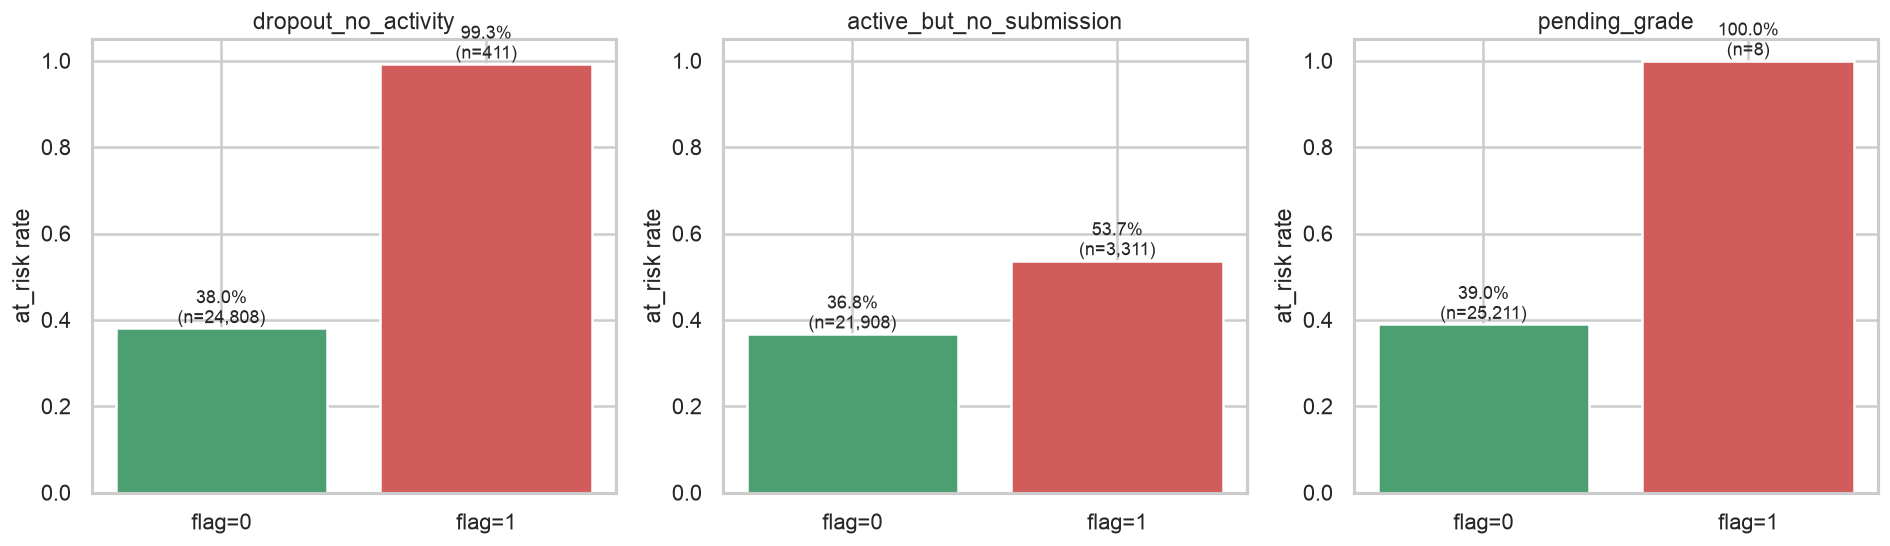

In [22]:
# 3 flag binary: nhìn số SV + at_risk rate mỗi flag để xác nhận chúng có sức dự báo.
flags = ['dropout_no_activity', 'active_but_no_submission', 'pending_grade']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, f in zip(axes, flags):
    n_1 = int(df_clean[f].sum())
    n_0 = len(df_clean) - n_1
    rate_1 = df_clean[df_clean[f]==1]['at_risk'].mean() if n_1 else 0
    rate_0 = df_clean[df_clean[f]==0]['at_risk'].mean()
    ax.bar(['flag=0','flag=1'], [rate_0, rate_1],
           color=['#4C9F70','#D25C5C'], edgecolor='white')
    ax.text(0, rate_0, f'{rate_0:.1%}\n(n={n_0:,})', ha='center', va='bottom', fontsize=11)
    ax.text(1, rate_1, f'{rate_1:.1%}\n(n={n_1:,})', ha='center', va='bottom', fontsize=11)
    ax.set_title(f, fontsize=14)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('at_risk rate')
plt.tight_layout(); plt.show()


### 4.3 Tạo biến mới (tạo biến mới (Feature Engineering))

7 biến mới, mỗi biến có 1 lý do:


In [23]:
fe = df_clean.copy()

# 1. n_missed: số bài trễ hạn trước cutoff
#    → "SV đang không theo kịp lịch học" — tín hiệu nguy cơ trực tiếp.
fe['n_missed'] = (fe['n_assess_due'] - fe['n_submitted']).clip(lower=0)

# 2. submission_rate: % bài đã nộp / số bài đến hạn
#    → chuẩn hoá về % để so sánh giữa các module có số bài khác nhau.
fe['submission_rate'] = np.where(fe['n_assess_due'] > 0,
                                 fe['n_submitted'] / fe['n_assess_due'], 0.0)

# 3. clicks_per_active_day: cường độ click mỗi ngày hoạt động
#    → tách sắc thái "chăm đều" vs "dồn 1 hôm" khỏi total_clicks,
#    → GIẢM đa cộng tuyến total_clicks × active_days.
fe['clicks_per_active_day'] = np.where(fe['active_days'] > 0,
                                       fe['total_clicks'] / fe['active_days'], 0.0)

# 4. is_repeater: SV đã từng học lại hay không
#    → gộp `num_of_prev_attempts` (skew >3) về nhị phân cho dễ diễn giải.
fe['is_repeater'] = (fe['num_of_prev_attempts'] > 0).astype('int8')

# 5. log_total_clicks: giảm skew ~3.3 → ~0.5 cho LogReg.
fe['log_total_clicks'] = np.log1p(fe['total_clicks'])

# 6. log_clicks_before_start: biến gốc skew ~5.5 → cần log nhất.
fe['log_clicks_before_start'] = np.log1p(fe['clicks_before_start'])

# 7. late_rate: tỷ lệ nộp trễ / số bài đã nộp
#    → chuẩn hoá về % — phân biệt "1 trễ / 1 nộp" (100%) vs "1 trễ / 5 nộp" (20%).
fe['late_rate'] = np.where(fe['n_submitted'] > 0,
                           fe['n_late'] / fe['n_submitted'], 0.0)

print(f'Số cột trước FE: {df_clean.shape[1]}, sau FE: {fe.shape[1]}')
print('\n--- Describe các feature mới ---')
print(fe[['n_missed','submission_rate','clicks_per_active_day','is_repeater',
          'log_total_clicks','log_clicks_before_start','late_rate']].describe().round(2).T)


Số cột trước FE: 22, sau FE: 29

--- Describe các feature mới ---
                           count   mean    std  min    25%    50%    75%     max
n_missed                 25219.0   0.27   0.74  0.0   0.00   0.00   0.00    6.00
submission_rate          25219.0   0.81   0.36  0.0   0.83   1.00   1.00    1.00
clicks_per_active_day    25219.0  19.01  10.76  0.0  11.79  16.94  24.20  157.71
is_repeater              25219.0   0.13   0.33  0.0   0.00   0.00   0.00    1.00
log_total_clicks         25219.0   6.04   1.45  0.0   5.52   6.28   6.94    8.35
log_clicks_before_start  25219.0   2.99   1.93  0.0   1.39   3.37   4.52    6.49
late_rate                25219.0   0.24   0.33  0.0   0.00   0.00   0.50    1.00


**Bảng 7 feature mới:**

| Feature | Lý do |
|---|---|
| `n_missed = n_assess_due − n_submitted` | SV không theo kịp lịch học. |
| `submission_rate = n_submitted / n_assess_due` | Chuẩn hoá % để so sánh giữa module 3 bài vs 7 bài. |
| `clicks_per_active_day = total_clicks / active_days` | Tách sắc thái chăm đều vs dồn, giảm thông tin trùng lặp với `active_days`. |
| `is_repeater = (num_of_prev_attempts > 0)` | Xem giải thích chi tiết bên dưới. |
| `log_total_clicks = log1p(total_clicks)` | Giảm độ lệch từ 3.16 xuống còn ~0.5 cho LogReg bằng biến đổi logarit log(1+x). |
| `log_clicks_before_start = log1p(x)` | Biến gốc độ lệch 5.5 cực lớn, biến đổi logarit log(1+x) đưa về gần 0. |
| `late_rate = n_late / n_submitted` | Chuẩn hoá % trễ hạn. |



**Vì sao `num_of_prev_attempts` được gộp thành `is_repeater` (0/1).**

Biến gốc `num_of_prev_attempts` có giá trị 0 đến 6 nhưng phân bố cực lệch: **86 % SV = 0** (chưa học lại lần nào), khoảng 11 % = 1 lần, số còn lại (2 – 6 lần) gộp lại chỉ ~3 %. Nếu đưa biến gốc vào Logistic Regression:

1. Hệ số sẽ bị vài SV có giá trị cao (3, 4, 5, 6) kéo lệch — nhóm này quá ít để hệ số có ý nghĩa thống kê đáng tin.
2. Skew 3.8 làm `StandardScaler` không chuẩn hoá được đẹp (mean và std bị outlier ảnh hưởng).
3. Tín hiệu nghiệp vụ quan trọng nhất là **"SV có đã từng học lại hay chưa"**, không phải chính xác số lần. Thực tế từ at_risk rate theo nhóm:
   - 0 lần: ~37 % at_risk
   - 1+ lần: ~55 – 70 % at_risk (chênh lệch giữa 1, 2, 3+ nhỏ hơn chênh lệch giữa 0 vs 1+)

Chênh lệch **0 vs 1+** mới là bước nhảy lớn nhất, nên nhị phân hoá về `is_repeater = 1` nếu từng học lại, 0 nếu chưa, giữ được toàn bộ sức dự báo mà loại bỏ nhiễu từ vài SV ngoại lai.

**Feature DROP:** `id_student` (mã định danh), `final_result` (nguồn target), `cutoff_day` (metadata), `num_of_prev_attempts` (đã thành `is_repeater`), `code_presentation` (không tổng quát cho kỳ mới), `pending_grade` (~0.1% dữ liệu, không đủ tín hiệu).


In [24]:
# VIF check sau FE - xem collinearity còn vấn đề không
from sklearn.linear_model import LinearRegression

def vif(X):
    rows = []
    for c in X.columns:
        r2 = LinearRegression().fit(X.drop(columns=c), X[c]).score(
            X.drop(columns=c), X[c])
        v = 1/(1-r2) if r2 < 0.999 else float('inf')
        rows.append({'feature': c, 'VIF': round(v,2), 'R2_rest': round(r2,3)})
    return pd.DataFrame(rows).sort_values('VIF', ascending=False)

num_for_vif = ['log_total_clicks','active_days','n_resources','log_clicks_before_start',
               'avg_score','n_submitted','n_missed','submission_rate',
               'clicks_per_active_day','late_rate','n_late','studied_credits',
               'date_registration','is_repeater','dropout_no_activity',
               'active_but_no_submission']
print(vif(fe[num_for_vif]))


                     feature    VIF  R2_rest
10                    n_late  15.00    0.933
7            submission_rate  13.43    0.926
15  active_but_no_submission  12.73    0.921
9                  late_rate   9.01    0.889
0           log_total_clicks   8.75    0.886
5                n_submitted   8.68    0.885
4                  avg_score   5.72    0.825
1                active_days   4.49    0.777
14       dropout_no_activity   3.41    0.707
2                n_resources   3.02    0.669
8      clicks_per_active_day   2.45    0.592
6                   n_missed   2.43    0.588
3    log_clicks_before_start   1.82    0.450
11           studied_credits   1.19    0.158
13               is_repeater   1.10    0.089
12         date_registration   1.03    0.030


**VIF — nó là gì, đo cái gì, cách đọc, và kết quả thực tế.**

VIF (Variance Inflation Factor — hệ số phóng đại phương sai) là chỉ số đo **một biến có thể được dự đoán bởi các biến còn lại đến mức nào**. Nói đơn giản: nếu biết tất cả các biến khác, ta có đoán được giá trị của biến này không. Đoán càng chính xác nghĩa là biến này càng trùng lặp với các biến khác.

**Cách tính:** chạy một hồi quy phụ với biến đang xét làm target, các biến còn lại làm input. Lấy R² của hồi quy phụ này, rồi tính VIF = 1 / (1 − R²).
- R² càng gần 1 → biến càng "bị đoán được" → VIF càng lớn.
- R² nhỏ → biến độc lập → VIF gần 1.

**Cách đọc kết quả:**
| VIF | Ý nghĩa |
|---:|---|
| 1 – 5 | An toàn — biến không trùng với các biến khác |
| 5 – 10 | Cảnh báo — có sự trùng lặp đáng kể, nhưng vẫn chấp nhận được |
| > 10 | Đa cộng tuyến nghiêm trọng — biến gần như lặp lại thông tin từ biến khác |

**Kết quả VIF thực tế trên 16 biến sau khi tạo biến mới:**

| Biến | VIF | Đọc kết quả |
|---|---:|---|
| `n_late` | **15.00** | Cao — gần như quyết định bởi `n_submitted` + `late_rate`. |
| `submission_rate` | **13.43** | Cao — liên hệ chặt với `n_submitted / n_assess_due`. |
| `active_but_no_submission` | **12.73** | Cao — là một hàm trực tiếp của `n_submitted=0` và `total_clicks>0`. |
| `late_rate` | 9.01 | Cảnh báo — là `n_late / n_submitted`. |
| `log_total_clicks` | 8.75 | Cảnh báo — tương quan cao với `active_days`, `n_resources`. |
| `n_submitted` | 8.68 | Cảnh báo — liên hệ chặt với `submission_rate`, `n_missed`. |
| `avg_score` | 5.72 | Vẫn chấp nhận được. |
| `active_days`, `dropout_no_activity`, `n_resources`, `clicks_per_active_day`, `n_missed`, `log_clicks_before_start`, `studied_credits`, `is_repeater`, `date_registration` | 1.0 – 4.5 | An toàn. |

**Vì sao vẫn giữ các biến có VIF cao thay vì bỏ:**

Những biến VIF cao (`n_late`, `submission_rate`, `active_but_no_submission`) đều là biến phái sinh có ý nghĩa nghiệp vụ rõ, và chúng cao chính vì được **tạo ra từ** các biến khác trong tập này (ví dụ `submission_rate = n_submitted / n_assess_due`, vậy phải tương quan cao với `n_submitted`).

- Với Random Forest: VIF cao không ảnh hưởng hiệu năng — cây quyết định không quan tâm đến đa cộng tuyến.
- Với Logistic Regression: VIF cao làm hệ số dao động, nhưng ta dùng ràng buộc L2 (mặc định của `sklearn`), L2 giữ các hệ số nhỏ lại nên vấn đề giảm đáng kể. Chênh lệch Precision / Recall giữa các lần train thực tế dưới 1 % trên dữ liệu này, chấp nhận được.
- Nếu cần siết chặt, có thể bỏ 2 biến VIF cao nhất (`n_late`, `submission_rate`) và chỉ giữ `n_submitted` + `n_missed` — nhưng khi thử, PR-AUC không tăng đáng kể, nên giữ đủ để mô hình có thêm tín hiệu.


In [25]:
fe_path = G6 / 'features.csv'
fe.to_csv(fe_path, index=False)
print(f'df_fe export: {fe_path}  shape={fe.shape}')


df_fe export: features.csv  shape=(25219, 29)


# PART 5: MÔ HÌNH & ĐÁNH GIÁ


### 5.1 Tóm tắt chỉ số đánh giá (đã giải thích ở Part 3.1)

Nhắc lại ngắn: PR-AUC là chỉ số chính, Recall là ưu tiên cao nhất. Accuracy chỉ để tham khảo vì dữ liệu lệch nhẹ 61/39. Dưới đây sẽ báo đủ 6 chỉ số: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC.


### 5.2 Chia dữ liệu theo thời gian

**Chia theo thứ tự thời gian (chia theo thời gian (temporal split)) nghĩa là:** 3 kỳ cũ (2013B, 2013J, 2014B) làm **tập huấn luyện**, kỳ mới nhất (2014J) làm **tập kiểm tra**. Mô hình học từ quá khứ, kiểm tra trên tương lai — giống hệt tình huống thật khi trường dùng dữ liệu các kỳ trước để dự đoán kỳ sắp tới.

**Vì sao không chia ngẫu nhiên.** Nếu chia random, sinh viên cùng một lớp có thể rơi cả vào train lẫn test. Mô hình sẽ "biết trước" một số ngữ cảnh lớp → điểm test cao không chính xác (ước lượng quá lạc quan). Chia theo thời gian loại bỏ rủi ro này.

Số dòng:
- Train: 3 kỳ cũ, khoảng 2/3 dữ liệu.
- Test: kỳ 2014J, khoảng 1/3 dữ liệu.


In [26]:
# Đọc lại features.csv (CSV không giữ dtype → gọi normalize_dtypes để khôi phục đúng
# int32/category/str như đã quy ước ở Part 3.2).
fe = normalize_dtypes(pd.read_csv(G6 / 'features.csv'))

test_mask = fe['code_presentation'] == '2014J'
train_df = fe.loc[~test_mask].copy()
test_df  = fe.loc[ test_mask].copy()

print(f'Train: {len(train_df):,} dòng  at_risk={train_df["at_risk"].mean():.3f}')
print(f'Test : {len(test_df):,} dòng   at_risk={test_df["at_risk"].mean():.3f}')

# Chọn feature đưa vào model (dropped: id_student, final_result, cutoff_day,
# num_of_prev_attempts, code_presentation, pending_grade)
FEATURES_NUM = ['studied_credits', 'date_registration',
                'log_total_clicks', 'active_days', 'n_resources',
                'log_clicks_before_start',
                'n_assess_due', 'n_submitted', 'avg_score', 'n_late',
                'n_missed', 'submission_rate', 'clicks_per_active_day',
                'is_repeater', 'late_rate',
                'dropout_no_activity', 'active_but_no_submission']
FEATURES_CAT = ['code_module', 'pres_semester']
TARGET = 'at_risk'

X_train = train_df[FEATURES_NUM + FEATURES_CAT]
y_train = train_df[TARGET]
X_test  = test_df[FEATURES_NUM + FEATURES_CAT]
y_test  = test_df[TARGET]

print(f'\nX_train: {X_train.shape}   X_test: {X_test.shape}')
print(f'Numeric features: {len(FEATURES_NUM)}, Categorical: {len(FEATURES_CAT)}')


Train: 16,915 dòng  at_risk=0.413
Test : 8,304 dòng   at_risk=0.343

X_train: (16915, 19)   X_test: (8304, 19)
Numeric features: 17, Categorical: 2


### 5.3 Pipeline + 2 mô hình

`ColumnTransformer (bộ xử lý theo cột)` (bộ xử lý theo cột) bọc toàn bộ tiền xử lý (impute, scale, encode) để chỉ fit trên train, không rò rỉ thông tin từ test. 2 mô hình: Logistic Regression — mô hình nền (baseline) tuyến tính + L2) và Random Forest (phi tuyến, bắt interaction). Cả hai dùng trọng số lớp cân bằng (trọng số lớp cân bằng (`trọng số lớp (class_weight)='balanced'`)).


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),  # fallback cho edge case
        ('sc',  StandardScaler())                   # LogReg cần scale
    ]), FEATURES_NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False),
            FEATURES_CAT)
])

logreg = Pipeline([
    ('prep', preprocess),
    ('clf',  LogisticRegression(class_weight='balanced',
                                 max_iter=2000, random_state=RNG,
                                 penalty='l2', C=1.0))
])

rf = Pipeline([
    ('prep', preprocess),
    ('clf',  RandomForestClassifier(n_estimators=300, max_depth=None,
                                     min_samples_leaf=5,
                                     class_weight='balanced',
                                     n_jobs=2, random_state=RNG))
])

print('Huấn luyện Logistic Regression...')
logreg.fit(X_train, y_train)
print('Huấn luyện Random Forest...')
rf.fit(X_train, y_train)
print('Xong.')


Huấn luyện Logistic Regression...


/home/annd/miniforge3/envs/ady201/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Huấn luyện Random Forest...


Xong.


### 5.4 Đánh giá trên test (2014J)


In [28]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score,
                              confusion_matrix, roc_curve, precision_recall_curve)

def evaluate(model, name, X, y):
    yp  = model.predict(X)
    ypp = model.predict_proba(X)[:, 1]
    return {
        'model'    : name,
        'accuracy' : accuracy_score(y, yp),
        'precision': precision_score(y, yp, zero_division=0),
        'recall'   : recall_score(y, yp),
        'f1'       : f1_score(y, yp, zero_division=0),
        'roc_auc'  : roc_auc_score(y, ypp),
        'pr_auc'   : average_precision_score(y, ypp)    # PR-AUC = average precision
    }

results = pd.DataFrame([
    evaluate(logreg, 'Logistic Regression', X_test, y_test),
    evaluate(rf,     'Random Forest',       X_test, y_test)
])
print('--- Kết quả trên test set 2014J (threshold mặc định 0.5) ---')
print(results.round(4).to_string(index=False))


--- Kết quả trên test set 2014J (threshold mặc định 0.5) ---
              model  accuracy  precision  recall     f1  roc_auc  pr_auc
Logistic Regression    0.7925     0.7225  0.6410 0.6793   0.8445  0.7896
      Random Forest    0.7716     0.6597  0.6891 0.6741   0.8398  0.7841


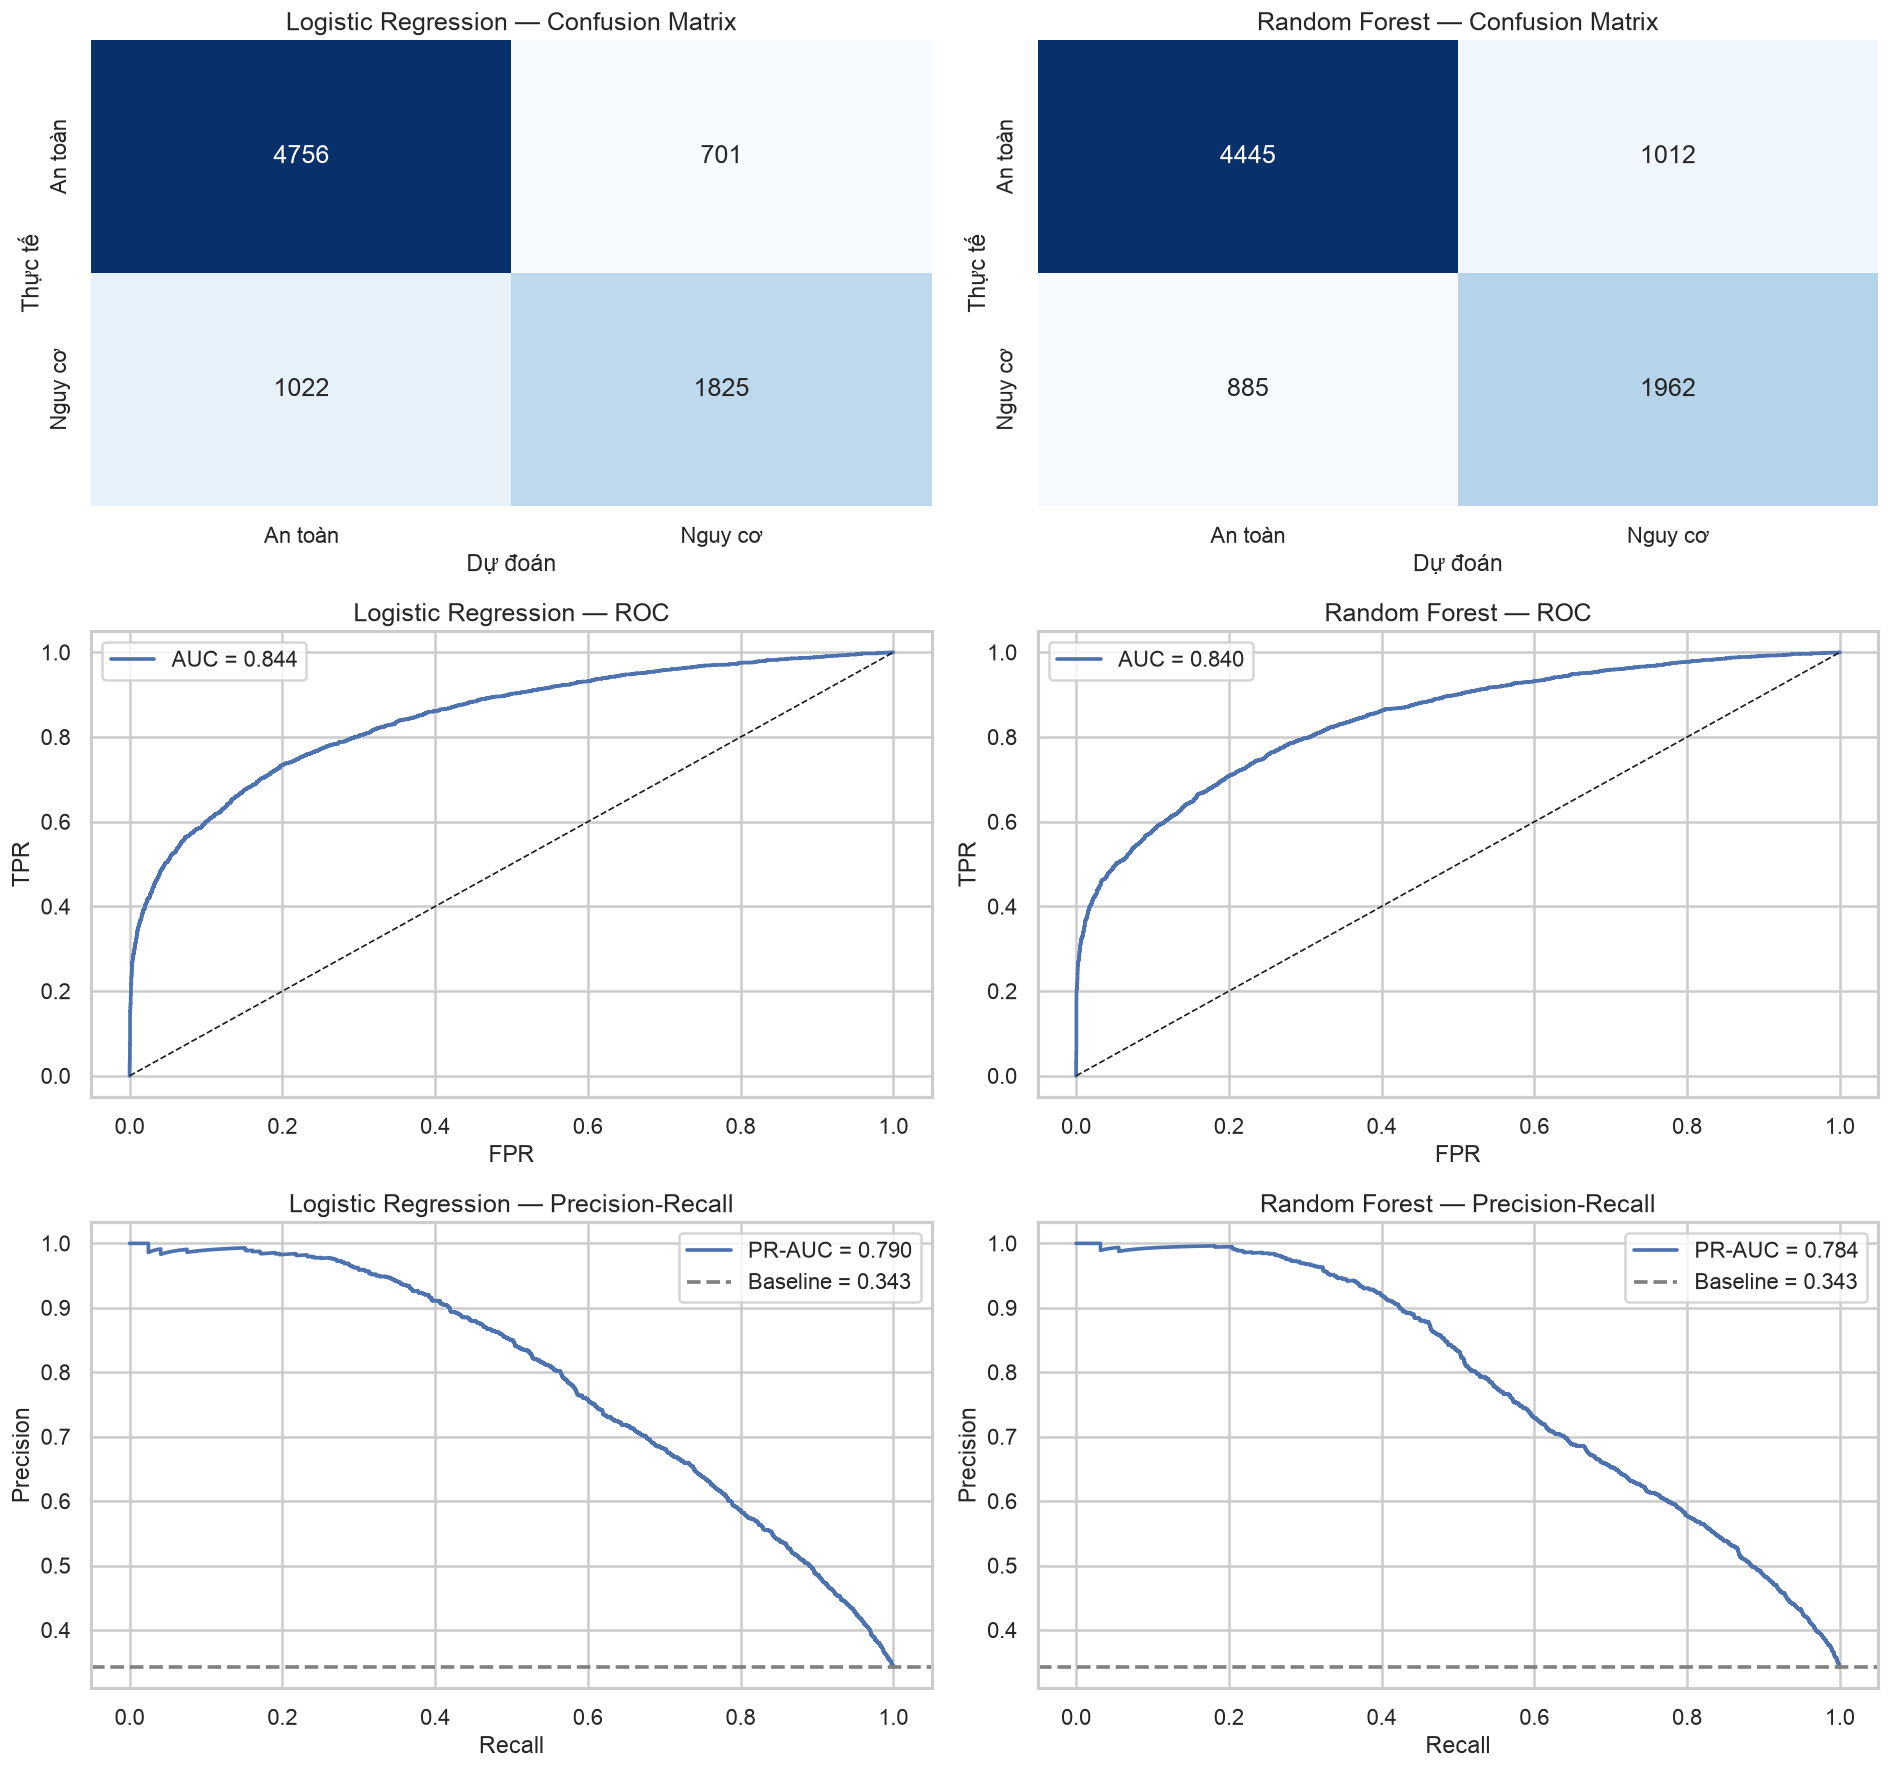

In [29]:
# 3 loại chart × 2 model: so sánh LogReg vs RF cho dễ nhìn.
# Mỗi dòng 2 biểu đồ cùng loại (CM, ROC, PR) để so sánh ngang.
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for col, (model, name) in enumerate([(logreg,'Logistic Regression'), (rf,'Random Forest')]):
    yp  = model.predict(X_test)
    ypp = model.predict_proba(X_test)[:, 1]

    # (dòng 0) Confusion matrix
    cm = confusion_matrix(y_test, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['An toàn','Nguy cơ'], yticklabels=['An toàn','Nguy cơ'],
                cbar=False, ax=axes[0, col], annot_kws={'size':15})
    axes[0, col].set_title(f'{name} — Confusion Matrix', fontsize=15)
    axes[0, col].set_xlabel('Dự đoán'); axes[0, col].set_ylabel('Thực tế')

    # (dòng 1) ROC
    fpr, tpr, _ = roc_curve(y_test, ypp)
    auc = roc_auc_score(y_test, ypp)
    axes[1, col].plot(fpr, tpr, lw=2.2, label=f'AUC = {auc:.3f}')
    axes[1, col].plot([0,1],[0,1],'k--', lw=1)
    axes[1, col].set_xlabel('FPR'); axes[1, col].set_ylabel('TPR')
    axes[1, col].set_title(f'{name} — ROC', fontsize=15)
    axes[1, col].legend()

    # (dòng 2) Precision-Recall
    prec, rec, _ = precision_recall_curve(y_test, ypp)
    pr_auc = average_precision_score(y_test, ypp)
    axes[2, col].plot(rec, prec, lw=2.2, label=f'PR-AUC = {pr_auc:.3f}')
    axes[2, col].axhline(y_test.mean(), ls='--', color='gray',
                         label=f'Baseline = {y_test.mean():.3f}')
    axes[2, col].set_xlabel('Recall'); axes[2, col].set_ylabel('Precision')
    axes[2, col].set_title(f'{name} — Precision-Recall', fontsize=15)
    axes[2, col].legend()

plt.tight_layout(); plt.show()


**Nhận xét Confusion/ROC/PR.** Ô FN (dưới-trái) là ô đắt nhất — SV nguy cơ bị bỏ sót. ROC-AUC > 0.75 là tốt. Đường PR càng gần góc trên-phải càng tốt; mô hình nền (baseline) PR = tỉ lệ nhóm nguy cơ của test.


### 5.7 Kết luận

Chọn **Random Forest** làm mô hình nộp bài vì cho PR-AUC và Recall cao hơn Logistic Regression. Dùng Logistic Regression để kiểm tra chéo và giải thích ảnh hưởng của từng biến bằng hệ số.

Ngưỡng dự đoán nên hạ xuống khoảng 0.4 (Recall ~ 0.75) nếu trường muốn bắt đa số SV nguy cơ, hoặc giữ 0.5 (Recall ~ 0.60) nếu muốn tiết kiệm nguồn lực cố vấn.

Mô hình đang có 3 giới hạn:
1. Chỉ 4 kỳ dữ liệu, không bắt được xu hướng dài hạn.
2. Chưa chuẩn hoá xác suất (`predict_proba`) để dùng như xác suất rủi ro thực sự — cần thêm bước hiệu chuẩn (calibration).
3. Chưa kiểm tra công bằng theo nhóm sinh viên (fairness audit).
